# Routing the commutes at tract level: Houston

05.2.1 ran the unit-size checks of 05.2 on the Houston table of 05.1 and saved the tracts
kept and the block flows between them, currently with the 20 km2 rule, which is still an
open choice for Houston (the 10 km2 rule of New York loses 36 % of its commuters, the 20 km2
rule 21 %, and keeping every tract with a worker-weighted point loses none). This notebook
follows 05.3 step by step on those files, so that the two areas are routed the same way.

| Step | What we do |
|---|---|
| 1. Inputs | What the routing needs and what is on disk: the files of 05.2.1, the OpenStreetMap extract, the timetables still to decide |
| 2. Tract flows | The kept block flows summed to tract pairs: how many pairs, how many workers, the strongest pairs |
| 3. Routing points | One point per tract, placed where its workers live, so that the routing starts and ends in the right place |
| 4. Street network | The streets of the area read from OpenStreetMap into cafein, once, and saved for every later step |
| 5. Snapping | Each routing point moved onto the nearest street inside its own tract, at most 1 km away |
| 6. Street modes | Car, bicycle and e-bike travel times between all routing points, joined to the tract flows: how many commutes are reached and how long they take |
| 7. Timetables | The transit feeds of the area fetched through transitio for the chosen Tuesday, and what is inside each |
| 8. Transit | The cafein transit network from the feeds and the extract, saved on scratch, and the transit travel times at the departure, joined to the flows next to the street modes |
| 9. Checking the feeds | What the validator flagged in each feed, which trips cafein left out and why, and which stops have no footpath |
| 10. Why transit does not reach | The unreached commutes split by cause: a home with no stop in walking range, a workplace with none, or both served but not connected |
| 11. Is it the departure time? | The same transit matrix for a departure at 07:00, to see how many of the unconnected commutes are a matter of the peak-only express buses having left |
| 12. Islands | Whether the unreached commutes cross between transit systems that never connect, and how far their stops are from the home and the work |
| 13. Which rule blocks them | For every unreached commute: no stop within a 120-minute walk of the home, none within 120 minutes of the work, or a transfer longer than 20 minutes, or no connecting service at all |
| 14. Summary | Why 30 % of the commutes have no transit itinerary, the assumptions and limits of the routing, and two maps: the homes beyond a two-hour walk of any stop and the workplaces that cannot be reached |


In [1]:
import json
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import time
import urllib.request
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.ops import nearest_points

import transitio
from cafein import StreetNetwork, TransportNetwork, TravelTimeMatrix
from cafein._streaming import read_shards


## Parameters

The OpenStreetMap extract is Geofabrik's Texas file (about 0.7 GB), clipped by cafein to
the bounding box of the kept tracts, since the area lies in one state. The street network
artifact goes to scratch, not beside the notebook: the project folder is near its quota.


In [2]:
CITY = "Houston"
YEAR = 2023
STRONGEST = 20                       # flows shown in the tables

RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting") / CITY.lower().replace(" ", "-")
TRACTS = RESULTS / f"tracts-kept-{YEAR}.parquet"
FLOWS = RESULTS / f"lodes-metro-od-JT01-{YEAR}-kept.parquet"
BLOCKS = RESULTS / f"lodes-metro-blocks-{YEAR}.parquet"

DATA = Path("/scratch/project_2010423/data")
OSM_URL = "https://download.geofabrik.de/north-america/us/texas-latest.osm.pbf"
OSM_PBF = DATA / "osm" / "texas-latest.osm.pbf"
COUNTRY = "US"    # legal default speed limits for ways without a maxspeed tag (car routing)

# Street network artifact built once from the extract and saved on scratch.
STREET_ARTIFACT = RESULTS / "houston-streets.cafein"

# Distances in metres are measured in UTM zone 15N, which covers the Houston area.
METRIC_CRS = "EPSG:32615"

# Snapping rule, as in London and New York: a point may be moved to the nearest street up to
# this far, and only to a street inside its own tract.
SNAP_DISTANCE_M = 1000

# Routing (step 6), as in New York. Car runs twice: free-flow, and with cafein's empirical
# intersection-delay model (Jaakkola 2013) at its "rush" profile to match the morning peak.
# Parking search time is left off. The e-bike rides the bicycle's streets at 17.4 km/h on the flat
# against the bicycle's 15.3, the mean trip speeds of pedelecs and conventional bicycles in
# Schleinitz et al. (2017) and cafein's defaults, set as in Helsinki; without an elevation model
# neither mode sees slopes. Matrices are streamed per query to scratch.
CAR_PROFILE = "rush"
STREET_QUERIES = {
    "car_freeflow": {"folder": "car", "query": {"transport_mode": "car"}},
    "car": {"folder": f"car-{CAR_PROFILE}", "query": {"transport_mode": "car", "intersection_delays": True, "profile": CAR_PROFILE}},
    "bicycle": {"folder": "bicycle", "query": {"transport_mode": "bicycle"}},
    "e_bike": {"folder": "e_bike", "query": {"transport_mode": "e_bike", "speeds": {"e_bike": 17.4}}},
}
STREET_MODES = list(STREET_QUERIES)
MATRICES = RESULTS / "matrices"
MATRICES.mkdir(parents=True, exist_ok=True)

# Transit (step 7). The same departure as New York, a normal Tuesday morning at 08:30; every feed
# transitio lists for Greater Houston runs on that date. Feeds are fetched for the polygon of the
# kept tracts.
DEPARTURE = "2026-11-10 08:30"
ACCESS_EGRESS_WALK_MIN = 30   # the walk to the first stop and from the last stop, capped as in 05.9 and 05.10 (cafein's default is 120); the transit matrix folder carries the number
DIAGNOSTIC_DEPARTURE = "2026-11-10 07:00"   # step 11 only: an earlier departure, to test the peak-only express services
GTFS_DIR = DATA / "gtfs" / CITY.lower().replace(" ", "-")
GTFS_DIR.mkdir(parents=True, exist_ok=True)

# Transit network (step 8), built once from the feeds and the extract, saved on scratch.
TRANSIT_ARTIFACT = RESULTS / "houston-transit.cafein"
# Step 13 only: the same network with stop-to-stop transfers of up to 60 minutes on foot
# instead of cafein's 20, to measure how many commutes the transfer cap alone blocks.
TRANSFER_TEST_MINUTES = 60
TRANSIT_ARTIFACT_TRANSFER = RESULTS / f"houston-transit-transfer{TRANSFER_TEST_MINUTES}.cafein"
MODES = STREET_MODES + ["transit"]


## 1. Inputs

What the routing needs and what is already on disk. The timetable row is the open
question: the area is served by METRO (Houston's local buses and light rail), with
smaller operators in the suburban counties.


In [3]:
inputs = pd.DataFrame([
    {"input": "tracts kept", "path": str(TRACTS), "exists": TRACTS.exists(), "source": "05.2.1, step 5"},
    {"input": "block flows between kept tracts", "path": str(FLOWS), "exists": FLOWS.exists(), "source": "05.2.1, step 5"},
    {"input": "block list with internal points", "path": str(BLOCKS), "exists": BLOCKS.exists(), "source": "05.1, LODES crosswalk"},
    {"input": "OpenStreetMap extract", "path": str(OSM_PBF), "exists": OSM_PBF.exists(), "source": "Geofabrik, Texas"},
    {"input": "GTFS timetables (transit)", "path": "", "exists": False, "source": "to decide: METRO Houston and the county operators"},
    {"input": "elevation model (slopes for cycling)", "path": "", "exists": False, "source": "to decide: optional"},
])
inputs


,input,path,exists,source
0,tracts kept,/scratch/project_2010423/carbon-advantage/comm...,True,"05.2.1, step 5"
1,block flows between kept tracts,/scratch/project_2010423/carbon-advantage/comm...,True,"05.2.1, step 5"
2,block list with internal points,/scratch/project_2010423/carbon-advantage/comm...,True,"05.1, LODES crosswalk"
3,OpenStreetMap extract,/scratch/project_2010423/data/osm/texas-latest...,True,"Geofabrik, Texas"
4,GTFS timetables (transit),,False,to decide: METRO Houston and the county operators
5,elevation model (slopes for cycling),,False,to decide: optional


## 2. Tract flows

The block flows of 05.2.1 summed to pairs of tracts, home tract to work tract, with the
number of workers on each pair. Every tract of a pair is one of the kept tracts, by
construction of the kept flows.


In [4]:
tracts = gpd.read_parquet(TRACTS)
flows = pd.read_parquet(FLOWS)
flows["from_id"] = flows["h_geocode"].str[:11]
flows["to_id"] = flows["w_geocode"].str[:11]
od = flows.groupby(["from_id", "to_id"], as_index=False)["S000"].sum().rename(columns={"S000": "workers"})
assert od["from_id"].isin(tracts["tract"]).all() and od["to_id"].isin(tracts["tract"]).all()
od.to_parquet(RESULTS / f"tract-od-{YEAR}.parquet", index=False)

print(f"{len(tracts):,} tracts; {len(flows):,} block pairs summed to {len(od):,} tract pairs carrying {od['workers'].sum():,} workers; "
      f"{od['from_id'].nunique():,} home tracts, {od['to_id'].nunique():,} work tracts")
print("workers per tract pair:")
display(od["workers"].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame().T)
print(f"pairs with one worker: {(od['workers'] == 1).mean():.1%} of pairs, {od.loc[od['workers'] == 1, 'workers'].sum() / od['workers'].sum():.1%} of workers; "
      f"within-tract pairs: {od.loc[od['from_id'] == od['to_id'], 'workers'].sum() / od['workers'].sum():.1%} of workers")


1,447 tracts; 1,867,546 block pairs summed to 608,483 tract pairs carrying 2,115,440 workers; 1,446 home tracts, 1,445 work tracts
workers per tract pair:


,count,mean,std,min,50%,90%,99%,max
workers,608483.0,3.5,8.6,1.0,2.0,7.0,32.0,574.0


pairs with one worker: 49.7% of pairs, 14.3% of workers; within-tract pairs: 2.1% of workers


In [5]:
county = tracts.set_index("tract")["NAMELSADCO"]
strongest = od.nlargest(STRONGEST, "workers").copy()
strongest["home county"] = county.loc[strongest["from_id"]].to_numpy()
strongest["work county"] = county.loc[strongest["to_id"]].to_numpy()
strongest.reset_index(drop=True)


,from_id,to_id,workers,home county,work county
0,48157673108,48157673108,574,Fort Bend County,Fort Bend County
1,48157674507,48201313102,533,Fort Bend County,Harris County
2,48167724200,48167724300,473,Galveston County,Galveston County
3,48157673201,48157673108,439,Fort Bend County,Fort Bend County
4,48201334101,48201313102,432,Harris County,Harris County
5,48201314003,48201313102,426,Harris County,Harris County
6,48201100001,48201100001,423,Harris County,Harris County
7,48157670903,48201313102,417,Fort Bend County,Harris County
8,48039660605,48201313102,400,Brazoria County,Harris County
9,48201413301,48201313102,380,Harris County,Harris County


## 3. Routing points

A router needs a point to start from and a point to arrive at. A tract is a polygon, so we
have to choose one point inside it to stand for everyone who lives there. The centre of the
polygon is a poor choice in a big tract: it can fall in a field or a reservoir while the
houses sit at one edge.

We do what the Census Bureau does for its "centers of population": we take the small
blocks inside the tract, each with a known point, and average those points, giving more
weight to the blocks where more workers live. The result sits in the built-up part of the
tract. Two safety rules: if a tract has no resident worker at all, or if the average lands
outside the tract's own polygon (which can happen in a tract shaped like a crescent), we
use a point that the geometry library guarantees to be inside the polygon instead.

The table says how many tracts got their point each way, and how far the point moved from
the plain centre. The map shows every point, with the fallback ones in orange.


In [6]:
blocks = pd.read_parquet(BLOCKS).set_index("tabblk2020")
residents = flows.groupby("h_geocode")["S000"].sum()
blocks["workers_home"] = residents.reindex(blocks.index, fill_value=0)
blocks["tract"] = blocks.index.str[:11]
blocks["wx"] = blocks["blklondd"] * blocks["workers_home"]
blocks["wy"] = blocks["blklatdd"] * blocks["workers_home"]
weighted = blocks.groupby("tract")[["wx", "wy", "workers_home"]].sum()
weighted["lon"] = weighted["wx"] / weighted["workers_home"]
weighted["lat"] = weighted["wy"] / weighted["workers_home"]

points = tracts[["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work", "geometry"]].to_crs("EPSG:4326")
points = points.merge(weighted[["lon", "lat"]], left_on="tract", right_index=True, how="left")
points["weighted_point"] = gpd.points_from_xy(points["lon"], points["lat"], crs="EPSG:4326")
points["representative_point"] = points.geometry.representative_point()
has_point = points["lon"].notna()
inside = has_point & gpd.GeoSeries(points["weighted_point"], crs="EPSG:4326").within(points.geometry)
points["method"] = np.where(inside, "weighted mean of block points", np.where(has_point, "representative point (mean outside)", "representative point (no resident workers)"))
points["point"] = np.where(inside, points["weighted_point"], points["representative_point"])
points["point"] = gpd.GeoSeries(points["point"], crs="EPSG:4326")

# How far the point sits from the tract's geometric centroid, in metres (projected).
metric = points.to_crs(METRIC_CRS)
points["shift_m"] = gpd.GeoSeries(points["point"], crs="EPSG:4326").to_crs(METRIC_CRS).distance(metric.geometry.centroid)

print("how the point of each tract was placed:")
display(points["method"].value_counts().to_frame("tracts"))
print("distance from the tract's geometric centroid (m):")
points["shift_m"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame().T


how the point of each tract was placed:


,tracts
method,
weighted mean of block points,1418
representative point (mean outside),28
representative point (no resident workers),1


distance from the tract's geometric centroid (m):


,count,mean,std,min,50%,90%,99%,max
shift_m,1447.0,298.0,338.0,1.0,182.0,685.0,1641.0,2744.0


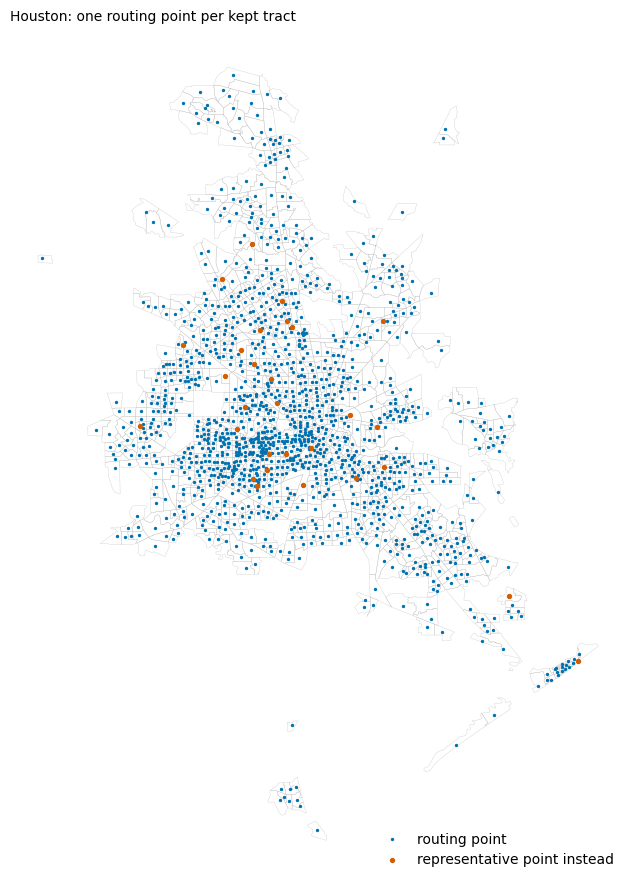

In [7]:
routing_points = gpd.GeoDataFrame({"id": points["tract"]}, geometry=points["point"].to_numpy(), crs="EPSG:4326")
routing_points.to_parquet(RESULTS / f"tract-points-{YEAR}.parquet", index=False)

figure, axis = plt.subplots(figsize=(11, 9))
points.plot(ax=axis, facecolor="none", edgecolor="#bbbbbb", linewidth=0.2)
routing_points.plot(ax=axis, color="#0072B2", markersize=2, label="routing point")
points.loc[points["method"] != "weighted mean of block points"].set_geometry("point").plot(ax=axis, color="#D55E00", markersize=8, label="representative point instead")
axis.legend(frameon=False, loc="lower right")
axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
axis.set_title(f"{CITY}: one routing point per kept tract", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()


## 4. Street network

The router needs the streets. They come from OpenStreetMap, in Geofabrik's file for the
whole of Texas, which the notebook downloads if it is not on disk yet. cafein reads the
file and keeps only the part inside the rectangle around the kept tracts, builds a graph
of streets usable on foot, by bicycle and by car, and fills in speed limits for streets
without one using the United States defaults. The network is saved on scratch; later runs
load it in seconds instead of rebuilding it. The printed line says how big it is.


In [8]:
if not OSM_PBF.exists():
    OSM_PBF.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(OSM_URL, OSM_PBF)
print(OSM_PBF.name, f"{OSM_PBF.stat().st_size / 1e9:.2f} GB")

bounding_box = tuple(tracts.to_crs("EPSG:4326").total_bounds)
started = time.time()
if STREET_ARTIFACT.exists():
    streets = StreetNetwork.load(STREET_ARTIFACT)
    print("loaded", STREET_ARTIFACT)
else:
    streets = StreetNetwork.from_osm(OSM_PBF, modes=("walk", "bicycle", "car"), country=COUNTRY, bounding_box=bounding_box)
    streets.save(STREET_ARTIFACT)
    print("built and saved", STREET_ARTIFACT)
print(f"{time.time() - started:.0f} s; bounding box {np.round(bounding_box, 3)}; vertices {streets.vertex_count:,}, edges {streets.edge_count:,}")


texas-latest.osm.pbf 0.73 GB


loaded /scratch/project_2010423/carbon-advantage/commuting/houston/houston-streets.cafein
2 s; bounding box [-95.998  28.95  -94.726  30.473]; vertices 3,938,331, edges 4,358,433


## 5. Snapping

A route has to begin and end on a street, and the point of step 3 usually sits inside a
block, a few metres from one. So each point is moved to the closest piece of street. Two
rules keep that honest: the street must lie inside the tract itself, so the point does not
jump into the neighbouring tract, and it may be at most 1 km away, otherwise the tract is
left without a point and the table lists it. Every segment of the street network counts
as a street, whether or not cars may use it.

The table says how far the points moved and which tracts, if any, were left out. The map
colours each tract by that distance and shows, for the centre of Houston, the points before
and after the move.


In [9]:
started = time.time()
edges = streets.streets_gdf[["geometry"]].to_crs(METRIC_CRS)
polygons = points[["tract", "geometry"]].to_crs(METRIC_CRS)
centres = gpd.GeoSeries(points["point"], crs="EPSG:4326").to_crs(METRIC_CRS)
print(f"{len(edges):,} edges in {METRIC_CRS}, {time.time() - started:.0f} s")

# Which edges touch which tract (an edge crossing a border appears in both tracts).
edges_in_tracts = gpd.sjoin(edges, polygons, how="inner", predicate="intersects")
print(f"{len(edges_in_tracts):,} edge-tract matches, {time.time() - started:.0f} s")

snapped = []
for (tract, polygon), centre in zip(polygons[["tract", "geometry"]].itertuples(index=False), centres):
    inside = edges_in_tracts.loc[edges_in_tracts["tract"] == tract, "geometry"]
    if len(inside) == 0:
        snapped.append({"tract": tract, "snap_distance_m": np.nan, "snapped": None})
        continue
    # Keep only the parts of the edges that lie inside the tract, then take the closest point.
    streets_inside = inside.intersection(polygon).union_all()
    point_on_street = nearest_points(centre, streets_inside)[1]
    snapped.append({"tract": tract, "snap_distance_m": centre.distance(point_on_street), "snapped": point_on_street})
snapped = pd.DataFrame(snapped)
points = points.drop(columns=[c for c in ["snap_distance_m", "snapped", "within_rule"] if c in points.columns]).merge(snapped, on="tract")
points["within_rule"] = points["snap_distance_m"] <= SNAP_DISTANCE_M
print(f"snapping done in {time.time() - started:.0f} s")

print(f"{len(points):,} tracts; {points['snap_distance_m'].isna().sum()} with no street inside at all; "
      f"{(~points['within_rule']).sum()} left without a point under the {SNAP_DISTANCE_M} m rule")
print("distance from the point to the snapped point (m):")
display(points["snap_distance_m"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame().T)
print("tracts left without a routable point:")
points.loc[~points["within_rule"], ["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work", "snap_distance_m"]].round(0)


4,358,433 edges in EPSG:32615, 32 s


3,220,668 edge-tract matches, 37 s


snapping done in 173 s
1,447 tracts; 1 with no street inside at all; 2 left without a point under the 1000 m rule
distance from the point to the snapped point (m):


,count,mean,std,min,50%,90%,99%,max
snap_distance_m,1446.0,27.0,43.0,0.0,19.0,50.0,174.0,1173.0


tracts left without a routable point:


,tract,NAMELSADCO,land_km2,workers_home,workers_work,snap_distance_m
577,48071710600,Chambers County,6.0,192.0,0.0,NaN
604,48167990100,Galveston County,0.0,0.0,724.0,1173.0


1,445 routing points saved; they carry 99.99% of the resident workers


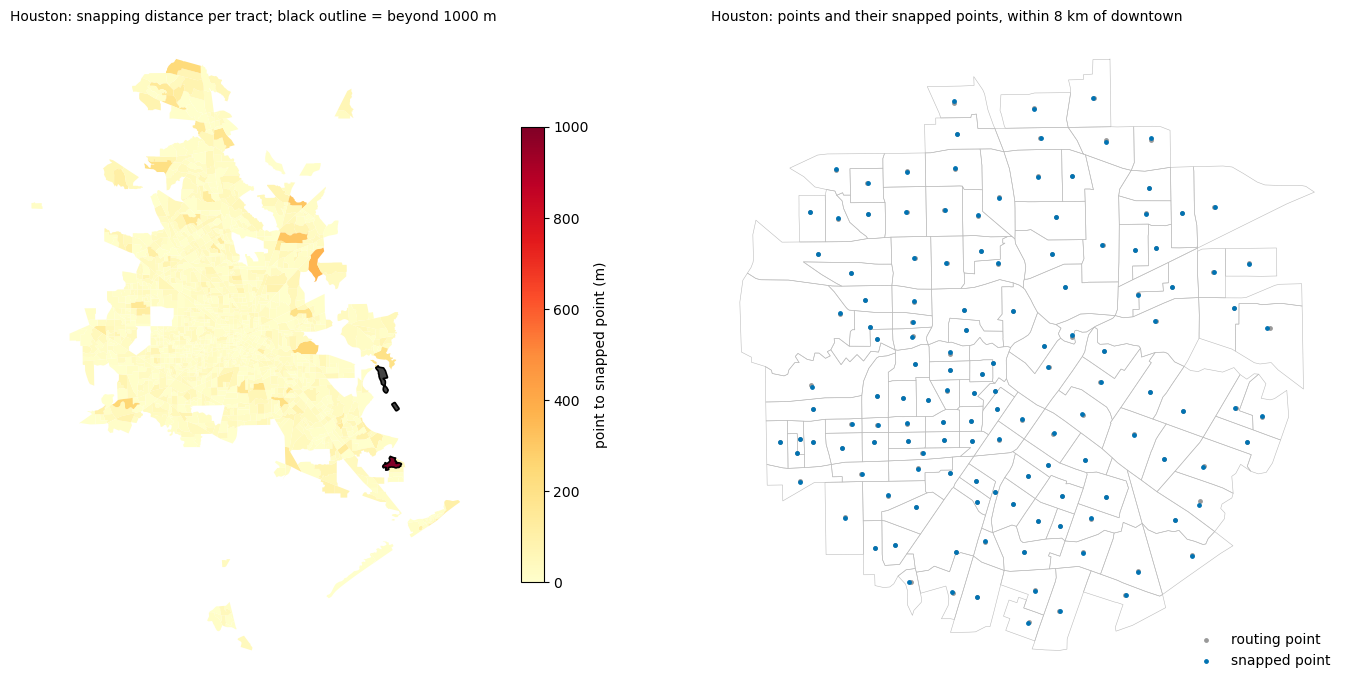

In [10]:
routing_points = gpd.GeoDataFrame(
    {"id": points.loc[points["within_rule"], "tract"].to_numpy()},
    geometry=points.loc[points["within_rule"], "snapped"].to_numpy(), crs=METRIC_CRS,
).to_crs("EPSG:4326")
routing_points.to_parquet(RESULTS / f"tract-points-snapped-{YEAR}.parquet", index=False)
print(f"{len(routing_points):,} routing points saved; they carry {points.loc[points['within_rule'], 'workers_home'].sum() / points['workers_home'].sum():.2%} of the resident workers")

figure, axes = plt.subplots(ncols=2, figsize=(16, 7))
points.plot(column="snap_distance_m", ax=axes[0], cmap="YlOrRd", vmin=0, vmax=SNAP_DISTANCE_M, edgecolor="none",
            legend=True, legend_kwds={"shrink": 0.7, "label": "point to snapped point (m)"},
            missing_kwds={"color": "#444444", "label": "no street inside"})
points.loc[~points["within_rule"]].plot(ax=axes[0], facecolor="none", edgecolor="black", linewidth=1.2)
axes[0].set_title(f"{CITY}: snapping distance per tract; black outline = beyond {SNAP_DISTANCE_M} m", loc="left", fontsize=10)

# The centre of Houston: the tracts within 8 km of downtown.
downtown = gpd.GeoSeries([gpd.points_from_xy([-95.3698], [29.7604])[0]], crs="EPSG:4326").to_crs(METRIC_CRS).iloc[0]
central = points.loc[polygons.geometry.centroid.distance(downtown).to_numpy() < 8000]
central.plot(ax=axes[1], facecolor="none", edgecolor="#bbbbbb", linewidth=0.4)
gpd.GeoSeries(central["point"], crs="EPSG:4326").plot(ax=axes[1], color="#999999", markersize=6, label="routing point")
gpd.GeoSeries(central["snapped"], crs=METRIC_CRS).to_crs("EPSG:4326").plot(ax=axes[1], color="#0072B2", markersize=6, label="snapped point")
axes[1].legend(frameon=False, loc="lower right")
axes[1].set_title(f"{CITY}: points and their snapped points, within 8 km of downtown", loc="left", fontsize=10)
for axis in axes:
    axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
    axis.set_axis_off()
figure.tight_layout()


## 6. Street modes

Now the routing itself, for the modes that need only streets. cafein computes the travel
time from every routing point to every other one, four times: by car as if the roads were
empty (free-flow), by car with the delays at junctions of the morning rush added, by
bicycle, and by e-bike. The e-bike rides the same streets as the bicycle at 17.4 km/h on the flat against the
bicycle's 15.3, the mean trip speeds of pedelecs and conventional bicycles in Schleinitz et
al. (2017) and cafein's defaults, set as in Helsinki; there is no elevation model here, so
neither mode is slowed by slopes. Each result is a table of about two million point pairs, written to scratch in
pieces so that a later run can reuse it instead of recomputing.

Then the tract flows of step 2 are joined to those tables: every pair of tracts gets its
workers, the straight-line distance between its two points, and its four times in
minutes. Two things to know when reading the numbers: a worker whose home and work are in
the same tract gets zero minutes, because the point routes to itself, and cafein stops a
street route at 120 minutes, so a bicycle trip longer than that counts as not reached.


In [11]:
def matrix_complete(path):
    # True when a streamed matrix folder has every shard completed.
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


for mode in STREET_MODES:
    output = MATRICES / STREET_QUERIES[mode]["folder"]
    if matrix_complete(output):
        print(f"{mode:12} complete -> {output}")
        continue
    started = time.time()
    TravelTimeMatrix.to_parquet(streets, routing_points, routing_points, output=output, output_time_units="seconds",
                                resume=output.exists(), **STREET_QUERIES[mode]["query"])
    print(f"{mode:12} {time.time() - started:6.0f} s -> {output}")


car_freeflow complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices/car
car          complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices/car-rush
bicycle      complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices/bicycle
e_bike       complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices/e_bike


In [12]:
od_times = od.loc[od["from_id"].isin(routing_points["id"]) & od["to_id"].isin(routing_points["id"])].copy()
coordinates = routing_points.set_index("id").geometry
home_lon, home_lat = coordinates.x.loc[od_times["from_id"]].to_numpy(), coordinates.y.loc[od_times["from_id"]].to_numpy()
work_lon, work_lat = coordinates.x.loc[od_times["to_id"]].to_numpy(), coordinates.y.loc[od_times["to_id"]].to_numpy()
od_times["straight_km"] = np.hypot((work_lon - home_lon) * np.cos(np.radians(home_lat)) * 111.32, (work_lat - home_lat) * 110.57)

for mode in STREET_MODES:
    matrix = read_shards(MATRICES / STREET_QUERIES[mode]["folder"])[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": f"{mode}_min"})
    matrix[f"{mode}_min"] = matrix[f"{mode}_min"] / 60
    od_times = od_times.merge(matrix, on=["from_id", "to_id"], how="left")
od_times.to_parquet(MATRICES / f"tract-od-times-{YEAR}.parquet", index=False)
print(f"{len(od_times):,} tract pairs with a flow between routing points, {od_times['workers'].sum():,} workers")
od_times.head()


608,199 tract pairs with a flow between routing points, 2,114,670 workers


,from_id,to_id,workers,straight_km,car_freeflow_min,car_min,bicycle_min,e_bike_min
0,48039660100,48039660100,27,0.000000,0.000000,0.000000,0.000000,0.000000
1,48039660100,48039660200,9,2.326989,5.000000,10.433333,17.333333,15.233333
2,48039660100,48039660301,12,4.253203,5.783333,18.000000,20.800000,18.300000
3,48039660100,48039660302,19,3.203895,6.583333,15.933333,18.816667,16.766667
4,48039660100,48039660303,6,2.778401,4.500000,11.016667,15.000000,13.183333


In [13]:
def weighted_percentiles(values, weights, percentiles):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return [values[order][np.searchsorted(cumulative, p / 100)] for p in percentiles]


def weighted_median(values, weights):
    return weighted_percentiles(values, weights, [50])[0]


def mode_summary(table, modes):
    # Worker-weighted summary of the travel times of each mode, over the pairs it reaches.
    summary = {}
    for mode in modes:
        reached = table[f"{mode}_min"].notna()
        minutes = table.loc[reached, f"{mode}_min"].to_numpy()
        weights = table.loc[reached, "workers"].to_numpy()
        straight = table.loc[reached, "straight_km"].to_numpy()
        summary[mode] = {
            "share of workers reached": weights.sum() / table["workers"].sum(),
            "mean minutes, worker-weighted": np.average(minutes, weights=weights),
            "median minutes, worker-weighted": weighted_median(minutes, weights),
            "p90 minutes, worker-weighted": weighted_percentiles(minutes, weights, [90])[0],
            # Straight-line distance covered per hour, over the pairs between different tracts.
            "straight-line km per hour, between tracts": straight[minutes > 0].dot(weights[minutes > 0]) / (minutes[minutes > 0] / 60).dot(weights[minutes > 0]),
        }
    return pd.DataFrame(summary)


print("commutes between the kept tracts, by mode:")
mode_summary(od_times, STREET_MODES).round(2)


commutes between the kept tracts, by mode:


,car_freeflow,car,bicycle,e_bike
share of workers reached,1.00,1.00,0.65,0.71
"mean minutes, worker-weighted",20.45,40.30,60.14,58.44
"median minutes, worker-weighted",18.30,38.45,59.43,57.12
"p90 minutes, worker-weighted",37.07,65.97,106.05,104.45
"straight-line km per hour, between tracts",64.53,32.50,12.32,14.08


median minutes per home tract, across tracts:


,count,mean,std,min,25%,50%,75%,max
car_freeflow_median_min,1445.0,18.2,6.9,0.0,13.6,17.7,21.8,69.4
car_median_min,1445.0,38.0,11.4,0.0,30.3,37.1,44.2,88.8
bicycle_median_min,1445.0,57.2,17.5,0.0,47.1,59.6,69.7,100.1
e_bike_median_min,1445.0,54.8,17.5,0.0,44.2,56.1,67.7,101.6


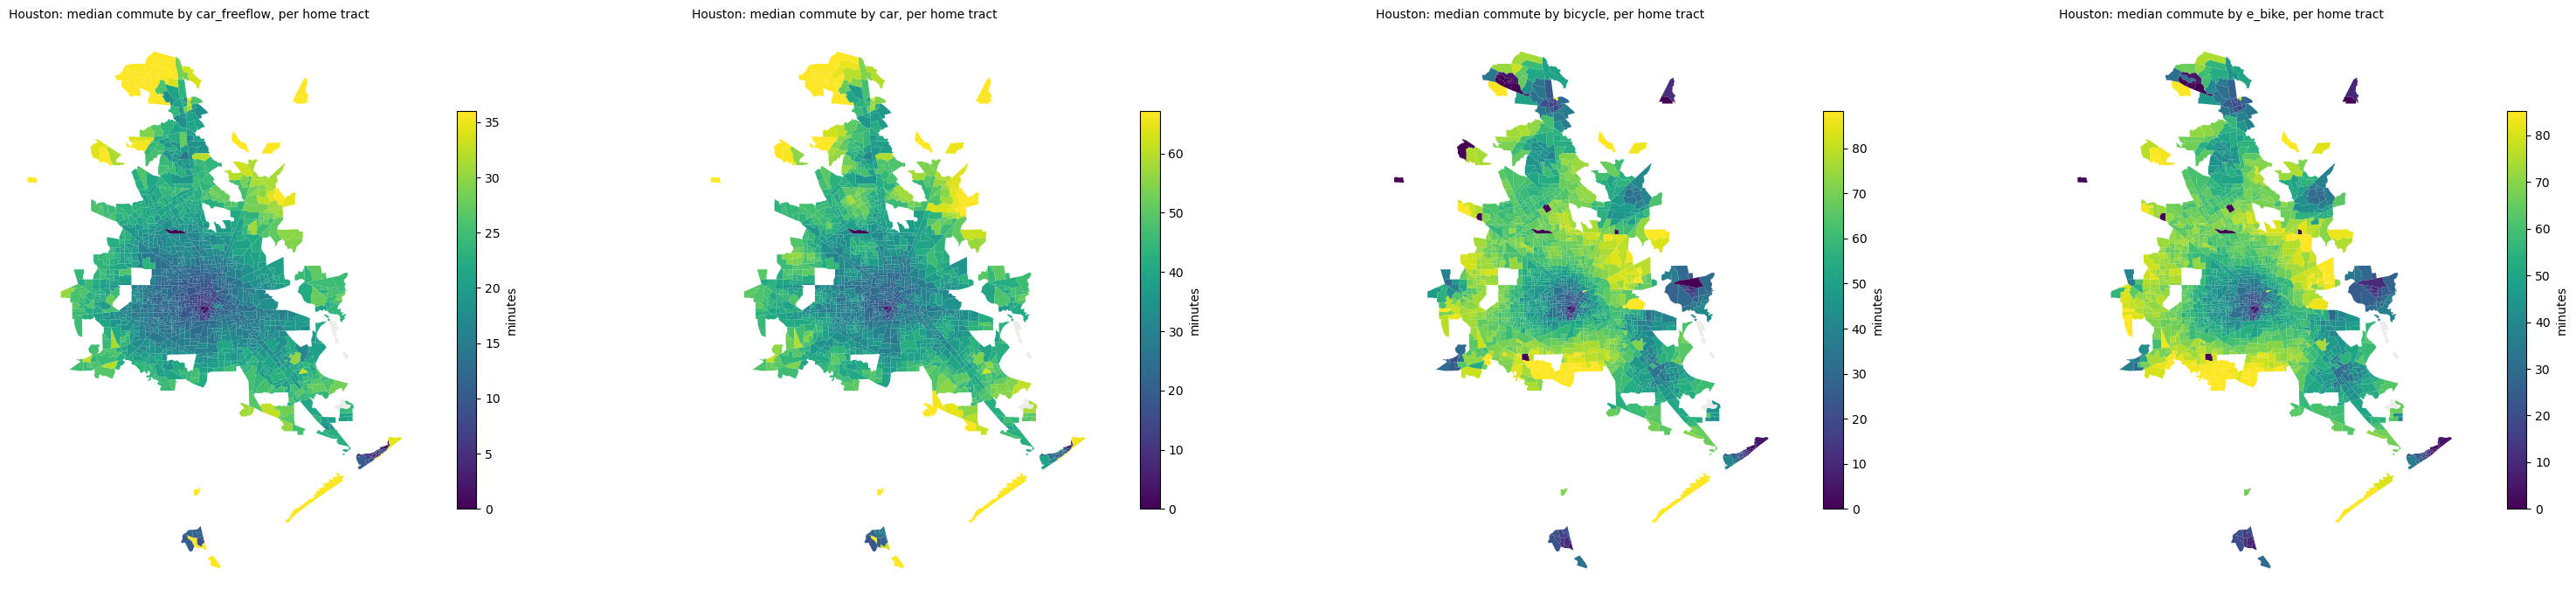

In [14]:
def median_by_home_tract(table, modes):
    # Worker-weighted median travel time of the residents of each home tract, per mode.
    per_tract = pd.DataFrame({"residents": table.groupby("from_id")["workers"].sum()})
    for mode in modes:
        column = f"{mode}_min"
        reached = table.loc[table[column].notna()]
        per_tract[f"{mode}_median_min"] = reached.groupby("from_id").apply(lambda rows: weighted_median(rows[column].to_numpy(), rows["workers"].to_numpy()), include_groups=False)
    return per_tract.rename_axis("tract").reset_index()


def map_medians(per_tract, modes):
    mapped = tracts[["tract", "geometry"]].merge(per_tract, on="tract", how="left")
    figure, axes = plt.subplots(ncols=len(modes), figsize=(8 * len(modes), 7))
    for axis, mode in zip(np.atleast_1d(axes), modes):
        column = f"{mode}_median_min"
        mapped.plot(column=column, ax=axis, cmap="viridis", vmin=0, vmax=np.nanpercentile(mapped[column], 98), edgecolor="none",
                    legend=True, legend_kwds={"shrink": 0.7, "label": "minutes"}, missing_kwds={"color": "#ececea"})
        axis.set_title(f"{CITY}: median commute by {mode}, per home tract", loc="left", fontsize=10)
        axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
        axis.set_axis_off()
    figure.tight_layout()


per_tract = median_by_home_tract(od_times, STREET_MODES)
per_tract.to_parquet(MATRICES / f"median-minutes-by-home-tract-{YEAR}.parquet", index=False)
map_medians(per_tract, STREET_MODES)
print("median minutes per home tract, across tracts:")
per_tract[[f"{mode}_median_min" for mode in STREET_MODES]].describe(percentiles=[0.25, 0.5, 0.75]).round(1).T


## 7. Timetables

Transit routing needs the timetables, which operators publish as GTFS files: lists of
stops, routes, trips and the times at every stop. transitio keeps an index of such files
for the whole world. We hand it the polygon of the kept tracts and a date, and it finds the
operators serving that polygon, downloads their files, checks them, repairs what it can
and drops the ones with no service on the date. For Houston the list is short: METRO, which
runs the city's buses and the three light rail lines, the Fort Bend, Woodlands and Gulf
Coast suburban operators, Galveston Island Transit and a few university shuttles.

The table says what is inside each file: operators, routes by type (0 tram, 1 metro,
2 rail, 3 bus, 4 ferry), stops, trips and the dates the timetable covers.


In [15]:
started = time.time()
area = tracts.to_crs("EPSG:4326").union_all()
fetched = transitio.fetch(aoi=area, when=pd.Timestamp(DEPARTURE).date(), osm=False, directory=GTFS_DIR)
print(f"transitio fetch done in {time.time() - started:.0f} s")
GTFS_FILES = [Path(str(feed)) for feed in fetched.feeds]
print(f"{len(GTFS_FILES)} feeds delivered, {sum(path.stat().st_size for path in GTFS_FILES) / 1e6:.0f} MB")
print("skipped:", fetched.skipped)
for report in fetched.reports:
    print("report:", str(report)[:400])


Fetching 14 feeds for the area


[1/14] f-uofhdowntownshuttle: cached copy reused


[2/14] f-9vk1-riceuniversity: cached copy reused


[3/14] f-galveston~tx~us: cached copy reused


[4/14] f-university~of~houston: cached copy reused


[5/14] f-mdb-ntd-60103: cached copy reused


... (10 outputs left out)

/tmp/marinflo/3372139/ipykernel_1795435/2904956454.py:3: UserWarning: no Mobility Database API token: the newest copies of f-mdb-625, f-mdb-593 do not run on 2026-11-10; with a token, fetch can pick a dated copy from the Mobility Database
  fetched = transitio.fetch(aoi=area, when=pd.Timestamp(DEPARTURE).date(), osm=False, directory=GTFS_DIR)


Comparing trips across 11 feeds


/tmp/marinflo/3372139/ipykernel_1795435/2904956454.py:3: UserWarning: trips left out as near repeats took departures at stops the trips they repeat do not serve: f-fortbendcountytexas~tx~us: 1 at 1 stops (32); duplicate_trips="exact" keeps near repeats
  fetched = transitio.fetch(aoi=area, when=pd.Timestamp(DEPARTURE).date(), osm=False, directory=GTFS_DIR)
Done in 20 s: 11 feeds delivered, 3 skipped, 42.5 MB downloaded


transitio fetch done in 20 s
11 feeds delivered, 15 MB
skipped: [('f-mdb-625', 'service ended 2022-07-01; unchanged since indexed'), ('f-mdb-593', 'service ended 2021-03-12; unchanged since indexed'), ('f-utel~uiuc~intercity~bus', 'service ended 2026-06-30')]
report: {'summary': {'validator': {'name': 'transitio', 'version': '0.28.0'}, 'generatedAt': '2026-11-24T09:22:07.017299+00:00', 'counts': {'errors': 0, 'warnings': 2, 'infos': 1}, 'suppressedNotices': 0, 'countsAreLowerBounds': False, 'serviceWindow': ['20200106', '20501230'], 'rowCounts': {'agency.txt': 1, 'calendar.txt': 2, 'frequencies.txt': 2, 'routes.txt': 2, 'shapes.txt': 602, 'stop_times.txt': 13,
report: {'summary': {'validator': {'name': 'transitio', 'version': '0.28.0'}, 'generatedAt': '2026-11-24T09:22:07.245468+00:00', 'counts': {'errors': 5, 'warnings': 15, 'infos': 2}, 'suppressedNotices': 0, 'countsAreLowerBounds': False, 'serviceWindow': ['20160213', '20501230'], 'rowCounts': {'agency.txt': 1, 'calendar.txt': 14, 

**Units of the shape distances.** cafein 0.31 decides per trip whether a feed's `shape_dist_traveled` is in metres or kilometres and takes feet for metres, which makes every ridden distance and the grams computed from it 3.28 times too large for operators that publish feet (CTA; Sound Transit, King County Metro and Intercity Transit). The script `jobs/fix-gtfs-shape-dist-units.py` decides the unit once per feed from its shapes and rewrites feet feeds in metres, in place; it runs here after every fetch, before the network is built, and leaves metre feeds alone.

In [ ]:
import subprocess
import sys

fix = subprocess.run([sys.executable, "../../jobs/fix-gtfs-shape-dist-units.py", str(GTFS_DIR), "--apply"], capture_output=True, text=True)
print(fix.stdout + fix.stderr)

In [16]:
ROUTE_TYPE_NAMES = {0: "tram", 1: "metro", 2: "rail", 3: "bus", 4: "ferry", 5: "cable tram", 6: "aerial", 7: "funicular", 11: "trolleybus", 12: "monorail"}


def gtfs_summary(path):
    # Counts and dates of one GTFS zip, without unpacking it to disk.
    with zipfile.ZipFile(path) as archive:
        names = set(archive.namelist())
        agency = pd.read_csv(archive.open("agency.txt"))
        routes = pd.read_csv(archive.open("routes.txt"))
        stops = pd.read_csv(archive.open("stops.txt"), usecols=["stop_id"])
        trips = pd.read_csv(archive.open("trips.txt"), usecols=["trip_id"])
        dates = []
        if "calendar.txt" in names:
            calendar = pd.read_csv(archive.open("calendar.txt"), dtype=str)
            dates += [calendar["start_date"].min(), calendar["end_date"].max()]
        if "calendar_dates.txt" in names:
            exceptions = pd.read_csv(archive.open("calendar_dates.txt"), dtype=str)
            dates += [exceptions["date"].min(), exceptions["date"].max()]
    by_type = routes["route_type"].map(lambda t: ROUTE_TYPE_NAMES.get(int(t), f"type {t}")).value_counts()
    return {"file": Path(path).name, "agencies": len(agency), "routes": len(routes), "stops": len(stops), "trips": len(trips),
            "first_date": min(dates) if dates else None, "last_date": max(dates) if dates else None, **{f"routes_{k}": v for k, v in by_type.items()}}


feeds = pd.DataFrame([gtfs_summary(path) for path in GTFS_FILES]).set_index("file").sort_values("trips", ascending=False)
feeds[[c for c in feeds.columns if c.startswith("routes_")]] = feeds[[c for c in feeds.columns if c.startswith("routes_")]].fillna(0).astype(int)
print(f"{len(feeds)} feeds, {feeds['trips'].sum():,} trips, {feeds['stops'].sum():,} stops")
feeds


11 feeds, 28,019 trips, 9,475 stops


,agencies,routes,stops,trips,first_date,last_date,routes_bus,routes_tram,routes_trolleybus,routes_rail
file,,,,,,,,,,
f-9vk-metropolitantransitauthorityofharriscounty.zip,1,109,8797,21878,20260830,20270213,106,3,0,0
f-galveston~tx~us.zip,1,11,292,5186,20251022,20271231,10,1,0,0
f-9-flixbus.zip,2,19,94,696,20261101,20270501,19,0,0,0
f-thewoodlandstownship~tx~us.zip,1,33,79,64,20250301,20311231,32,0,1,0
f-gulfcoasttransitdistrict~tx~us.zip,1,4,15,54,20240201,20271201,4,0,0,0
f-mdb-ntd-60103.zip,1,28,22,49,20230829,20281230,28,0,0,0
f-fortbendcountytexas~tx~us.zip,1,26,43,47,20250101,20300101,26,0,0,0
f-9vk1-riceuniversity.zip,1,14,73,20,20160210,20501230,14,0,0,0
f-university~of~houston.zip,1,5,28,13,20250811,20501230,5,0,0,0


## 8. Transit

cafein now combines the eleven timetables with the street map into one transit network:
the stops are linked to the streets so that a trip can walk to a stop, ride, change and
walk again. Built once and saved on scratch; later runs load it. Then it computes the
transit travel time from every routing point to every other one for a departure at 08:30
on the chosen Tuesday, with the walk to the first stop and from the last stop capped at 30 minutes, as in 05.9 and 05.10, and cafein's defaults for the transfers,
streamed to scratch like the street matrices.

The transit times join the table of step 6, so each pair of tracts now carries four times.
The summary and the maps are repeated for all modes.


In [17]:
started = time.time()
if TRANSIT_ARTIFACT.exists():
    transit_network = TransportNetwork.load(TRANSIT_ARTIFACT)
    print("loaded", TRANSIT_ARTIFACT)
else:
    transit_network = TransportNetwork.from_gtfs(GTFS_FILES, osm_pbf=OSM_PBF, street_modes=("walk", "bicycle", "car"),
                                                 country=COUNTRY, bounding_box=bounding_box)
    transit_network.save(TRANSIT_ARTIFACT)
    print("built and saved", TRANSIT_ARTIFACT)
print(f"{time.time() - started:.0f} s; {transit_network.stop_count:,} stops, {transit_network.trip_count:,} trips")


loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

loaded /scratch/project_2010423/carbon-advantage/commuting/houston/houston-transit.cafein
4 s; 9,475 stops, 29,057 trips


In [18]:
output = MATRICES / f"transit-walk{ACCESS_EGRESS_WALK_MIN}"
if matrix_complete(output):
    print(f"transit      complete -> {output}")
else:
    started = time.time()
    TravelTimeMatrix.to_parquet(transit_network, routing_points, routing_points, output=output, departure=DEPARTURE, max_walking_time=ACCESS_EGRESS_WALK_MIN,
                                output_time_units="seconds", resume=output.exists())
    print(f"transit      {time.time() - started:6.0f} s -> {output}")

matrix = read_shards(output)[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "transit_min"})
matrix["transit_min"] = matrix["transit_min"] / 60
od_times = od_times.drop(columns=[c for c in ["transit_min"] if c in od_times.columns]).merge(matrix, on=["from_id", "to_id"], how="left")
od_times.to_parquet(MATRICES / f"tract-od-times-{YEAR}.parquet", index=False)
# Steps 10 to 14 were written on the routing with cafein's default 120-minute walk, kept in matrices/transit;
# it joins as transit_uncapped_min for them, and transit_min above is the capped time the pipeline uses.
uncapped = read_shards(MATRICES / "transit")[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "transit_uncapped_min"})
uncapped["transit_uncapped_min"] = uncapped["transit_uncapped_min"] / 60
od_times = od_times.drop(columns=[c for c in ["transit_uncapped_min"] if c in od_times.columns]).merge(uncapped, on=["from_id", "to_id"], how="left")
od_times.to_parquet(MATRICES / f"tract-od-times-{YEAR}.parquet", index=False)

print("commutes between the kept tracts, by mode:")
mode_summary(od_times, MODES).round(2)


transit      complete -> /scratch/project_2010423/carbon-advantage/commuting/houston/matrices/transit-walk30


commutes between the kept tracts, by mode:


,car_freeflow,car,bicycle,e_bike,transit
share of workers reached,1.00,1.00,0.65,0.71,0.32
"mean minutes, worker-weighted",20.45,40.30,60.14,58.44,81.82
"median minutes, worker-weighted",18.30,38.45,59.43,57.12,75.78
"p90 minutes, worker-weighted",37.07,65.97,106.05,104.45,131.73
"straight-line km per hour, between tracts",64.53,32.50,12.32,14.08,9.29


median minutes per home tract, across tracts:


,count,mean,std,min,25%,50%,75%,max
car_freeflow_median_min,1445.0,18.2,6.9,0.0,13.6,17.7,21.8,69.4
car_median_min,1445.0,38.0,11.4,0.0,30.3,37.1,44.2,88.8
bicycle_median_min,1445.0,57.2,17.5,0.0,47.1,59.6,69.7,100.1
e_bike_median_min,1445.0,54.8,17.5,0.0,44.2,56.1,67.7,101.6
transit_median_min,1440.0,45.2,68.9,0.0,0.0,42.3,77.5,1017.8


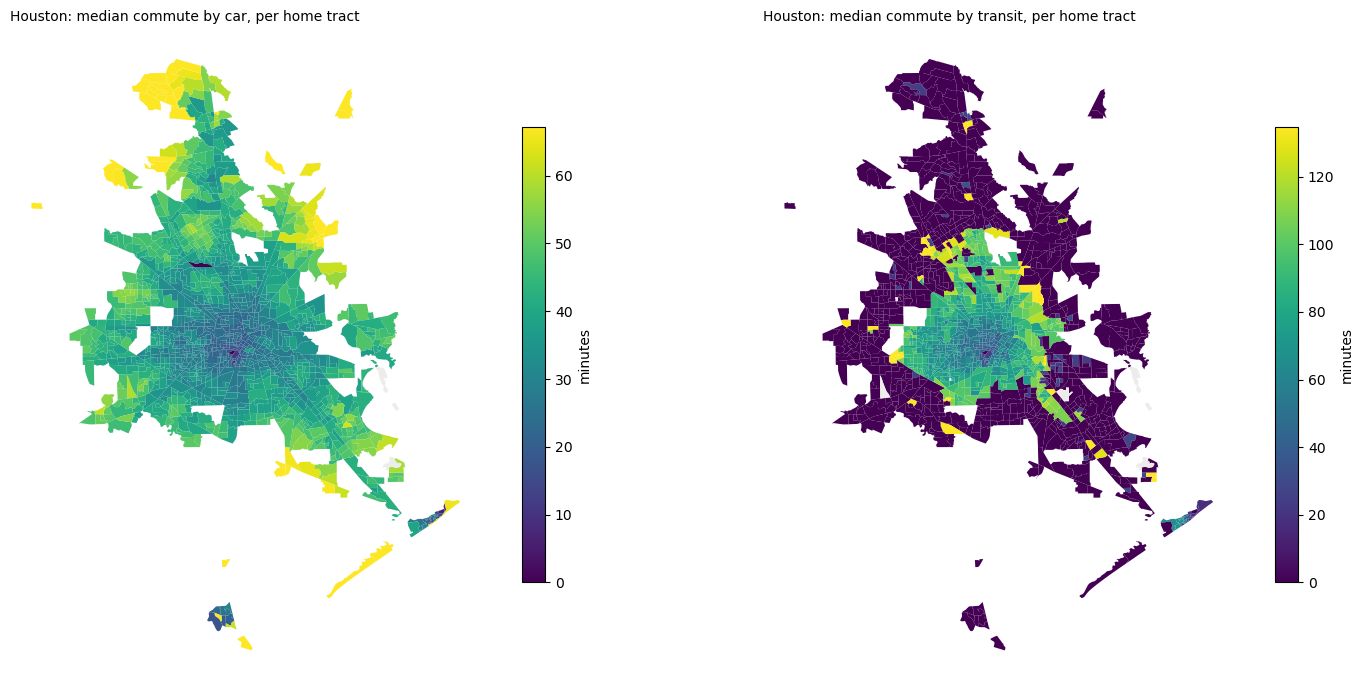

In [19]:
per_tract = median_by_home_tract(od_times, MODES)
per_tract.to_parquet(MATRICES / f"median-minutes-by-home-tract-{YEAR}.parquet", index=False)
map_medians(per_tract, ["car", "transit"])
print("median minutes per home tract, across tracts:")
per_tract[[f"{mode}_median_min" for mode in MODES]].describe(percentiles=[0.25, 0.5, 0.75]).round(1).T


## 9. Checking the feeds

The build of step 8 printed three warnings: 2,878 trips were quarantined for data-quality
problems, two trips had blank stop times filled in, and 103 stops lie more than 1.6 km
from the walking network and got no footpath. This step says what that means in practice.

First, the validation report of each feed as transitio produced it: the number of errors
and the error codes with one example each. Then the trips: for each feed, how many trips
its file holds, how many cafein kept, and for the feed losing most trips, which routes and
service days those trips belong to and whether they run on our Tuesday. Last, the stops
without a footpath: where they are and which operators they belong to. A stop without a
footpath can still be reached by riding, but nobody can walk to it or from it.


In [20]:
def error_notices(report):
    # The error-level notices of one transitio report, as (code, count, sample) rows.
    notices = report.get("notices", []) if isinstance(report, dict) else getattr(report, "notices", [])
    rows = []
    for notice in notices:
        if str(notice.get("severity", "")).upper() != "ERROR":
            continue
        sample = notice.get("sampleNotices", [None])
        rows.append((notice.get("code"), notice.get("totalNotices", len(sample)), str(sample[0] if sample else "")[:120]))
    return rows


feed_ids = list(fetched.paths)
for feed_id, report in zip(feed_ids, fetched.reports):
    summary = report.get("summary", {}) if isinstance(report, dict) else {}
    counts = summary.get("counts", {})
    print(f"{feed_id}: {counts.get('errors', '?')} errors, {counts.get('warnings', '?')} warnings")
    for code, count, sample in error_notices(report):
        print(f"    {code} x{count}: {sample}")


f-uofhdowntownshuttle: 0 errors, 2 warnings
f-9vk1-riceuniversity: 5 errors, 15 warnings
    block_trips_with_overlapping_stop_times x4: {'blockId': 'Night Escort_01', 'csvRowNumber': 146, 'tripIdA': 'TL-160', 'tripIdB': 'TL-161'}
    unusable_trip x1: {'csvRowNumber': 241, 'tripId': 'TL-39'}
f-galveston~tx~us: 0 errors, 15 warnings
f-university~of~houston: 6 errors, 5 warnings
    block_trips_with_overlapping_stop_times x6: {'blockId': 'TL-135_TL-44_UHSL', 'csvRowNumber': 57, 'tripIdA': 'TL-805', 'tripIdB': 'TL-806'}
f-mdb-ntd-60103: 5 errors, 0 warnings
    duplicate_key x5: {'csvRowNumber': 11, 'fieldNames': 'fare_id, route_id, origin_id, destination_id, contains_id', 'filename': 'fare_rules.
f-fortbendcountytexas~tx~us: 0 errors, 1 warnings
f-thewoodlandstownship~tx~us: 0 errors, 0 warnings
f-gulfcoasttransitdistrict~tx~us: 5 errors, 1 warnings
    equal_shape_distance_diff_coordinates x5: {'csvRowNumber': 4129, 'prevCsvRowNumber': 4128, 'shapeId': 'P&R'}
f-9vk-metropolitantransita

In [21]:
kept = pd.DataFrame(transit_network.trips, columns=["trip_id", "route_id"])
kept_ids = set(kept["trip_id"])
rows = []
missing_by_feed = {}
for index, path in enumerate(GTFS_FILES):
    with zipfile.ZipFile(path) as archive:
        trips = pd.read_csv(archive.open("trips.txt"), dtype=str)
    # cafein qualifies ids as <feed_index>:<id> when feeds collide; try both spellings.
    in_network = trips["trip_id"].isin(kept_ids) | (f"{index}:" + trips["trip_id"]).isin(kept_ids)
    rows.append({"feed": path.name, "trips in file": len(trips), "trips kept": int(in_network.sum()), "trips left out": int((~in_network).sum())})
    missing_by_feed[path] = trips.loc[~in_network]
trip_counts = pd.DataFrame(rows).set_index("feed").sort_values("trips left out", ascending=False)
print(f"{trip_counts['trips in file'].sum():,} trips in the files, {trip_counts['trips kept'].sum():,} kept by cafein ({transit_network.trip_count:,} routable)")
display(trip_counts)

worst = trip_counts.index[0]
worst_path = next(path for path in GTFS_FILES if path.name == worst)
missing = missing_by_feed[worst_path]
with zipfile.ZipFile(worst_path) as archive:
    names = set(archive.namelist())
    routes = pd.read_csv(archive.open("routes.txt"), dtype=str)
    stop_times = pd.read_csv(archive.open("stop_times.txt"), dtype=str)
    calendar = pd.read_csv(archive.open("calendar.txt"), dtype=str) if "calendar.txt" in names else pd.DataFrame()
    exceptions = pd.read_csv(archive.open("calendar_dates.txt"), dtype=str) if "calendar_dates.txt" in names else pd.DataFrame()
day = pd.Timestamp(DEPARTURE)
weekday = day.day_name().lower()
running = set()
if len(calendar):
    active = calendar[(calendar[weekday] == "1") & (calendar["start_date"] <= day.strftime("%Y%m%d")) & (calendar["end_date"] >= day.strftime("%Y%m%d"))]
    running |= set(active["service_id"])
if len(exceptions):
    on_day = exceptions[exceptions["date"] == day.strftime("%Y%m%d")]
    running |= set(on_day.loc[on_day["exception_type"] == "1", "service_id"])
    running -= set(on_day.loc[on_day["exception_type"] == "2", "service_id"])
missing = missing.merge(routes[["route_id", "route_short_name", "route_long_name"]], on="route_id", how="left")
missing["runs on the departure day"] = missing["service_id"].isin(running)
stops_per_trip = stop_times.groupby("trip_id").size()
missing["stop_times"] = missing["trip_id"].map(stops_per_trip).fillna(0).astype(int)
print(f"{worst}: {len(missing):,} trips left out, {missing['runs on the departure day'].sum():,} of them scheduled on {day.date()}; "
      f"stop times per left-out trip: min {missing['stop_times'].min()}, median {missing['stop_times'].median():.0f}")
print("left-out trips by route and service:")
missing.groupby(["route_short_name", "route_long_name", "service_id", "runs on the departure day"]).size().rename("trips").sort_values(ascending=False).head(25).to_frame()


28,019 trips in the files, 28,018 kept by cafein (29,057 routable)


,trips in file,trips kept,trips left out
feed,,,
f-9vk1-riceuniversity.zip,20,19,1
f-uofhdowntownshuttle.zip,2,2,0
f-galveston~tx~us.zip,5186,5186,0
f-university~of~houston.zip,13,13,0
f-mdb-ntd-60103.zip,49,49,0
f-fortbendcountytexas~tx~us.zip,47,47,0
f-thewoodlandstownship~tx~us.zip,64,64,0
f-gulfcoasttransitdistrict~tx~us.zip,54,54,0
f-9vk-metropolitantransitauthorityofharriscounty.zip,21878,21878,0


f-9vk1-riceuniversity.zip: 1 trips left out, 1 of them scheduled on 2026-11-10; stop times per left-out trip: min 1, median 1
left-out trips by route and service:


,,,,trips
route_short_name,route_long_name,service_id,runs on the departure day,


103 of 9,475 stops have no footpath
their names, most common first:


,stops
name,
Alpine Amtrak Station,1
Benson Amtrak,1
Beaumont Amtrak,1
Deming Amtrak,1
Del Rio Amtrak Station,1
El Paso,1
Los Angeles,1
Lake Charles,1
Lordsburg Amtrak,1


0 of the 103 stops without a footpath lie inside the area; the rest are intercity stops outside it


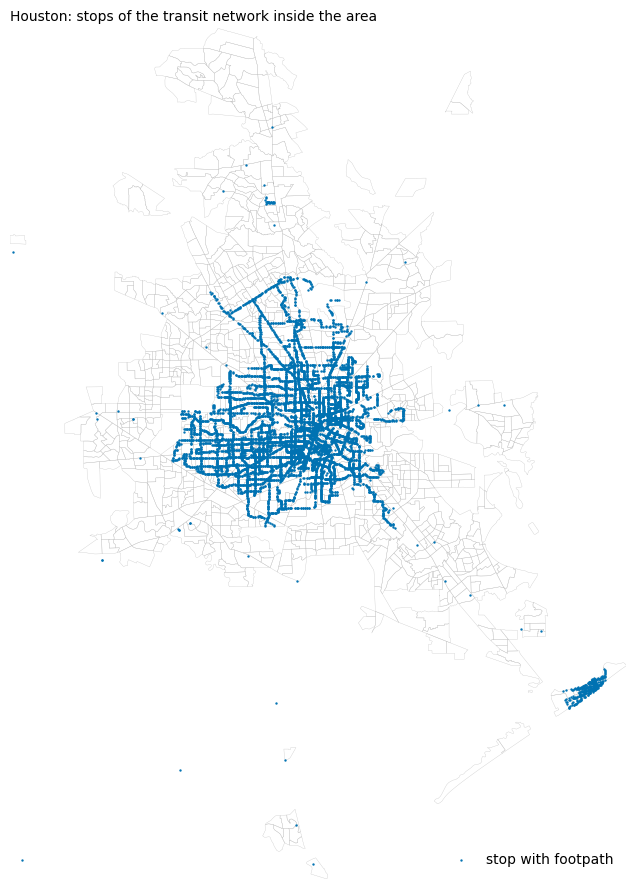

In [22]:
stops_all = transit_network.stops_gdf
with_footpath = set(transit_network.connectors_gdf["id"])
orphans = stops_all.loc[~stops_all["id"].isin(with_footpath)].copy()
print(f"{len(orphans):,} of {len(stops_all):,} stops have no footpath")
print("their names, most common first:")
display(orphans["name"].value_counts().head(10).to_frame("stops"))

# The feeds of Amtrak and Flixbus carry stops across the southern United States, so the
# view is clipped to the area; the stops outside it are counted instead of drawn.
west, south, east, north = tracts.to_crs("EPSG:4326").total_bounds
in_view = orphans.cx[west:east, south:north]
print(f"{len(in_view)} of the {len(orphans)} stops without a footpath lie inside the area; the rest are intercity stops outside it")

figure, axis = plt.subplots(figsize=(10, 9))
tracts.to_crs("EPSG:4326").plot(ax=axis, facecolor="none", edgecolor="#bbbbbb", linewidth=0.2)
stops_all.plot(ax=axis, color="#0072B2", markersize=0.5, label="stop with footpath")
if len(in_view):
    in_view.plot(ax=axis, color="#D55E00", markersize=20, label="stop without footpath")
axis.set_xlim(west, east)
axis.set_ylim(south, north)
axis.legend(frameon=False, loc="lower right")
axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
axis.set_title(f"{CITY}: stops of the transit network inside the area", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()


## 10. Why transit does not reach

> Note (2026-11-24): steps 10 to 14 analyse the routing with cafein's default 120-minute walk at each end, which they were written on; it stays in `matrices/transit` and joins the table as `transit_uncapped_min`. The transit time of step 8, which the pipeline uses, is now capped at 30 minutes at each end (`matrices/transit-walk30`).

Thirty percent of the commutes got no transit time. cafein lets a traveller walk up to
120 minutes at 3.6 km/h to reach a stop, so "unreached" is not about a short walk being
too long. A pair is unreached when the home point cannot reach any stop with service, when
the work point cannot be reached from any stop, or when both are served but no sequence
of rides connects them on that morning.

The full transit matrix says which it is. A routing point that reaches no other point at
all is isolated at the home end; one that no point reaches is isolated at the work end.
The unreached workers are split between those cases. Each point also gets its straight-line
distance to the nearest stop, which shows the isolated points are the ones far from any
stop, not a routing accident.


In [23]:
transit_matrix = read_shards(MATRICES / "transit")[["from_id", "to_id", "travel_time"]]
# A point reaches itself in zero seconds; that pair says nothing about transit, so it is left out.
transit_matrix = transit_matrix.loc[transit_matrix["from_id"] != transit_matrix["to_id"]]
reach_from = transit_matrix.groupby("from_id", observed=True)["travel_time"].apply(lambda s: s.notna().mean()).rename("share_reached_as_origin")
reach_to = transit_matrix.groupby("to_id", observed=True)["travel_time"].apply(lambda s: s.notna().mean()).rename("share_reached_as_destination")

# Straight-line distance from each routing point to the nearest stop of the network.
stops_metric = stops_all.dropna(subset=["geometry"]).to_crs(METRIC_CRS)[["id", "geometry"]].rename(columns={"id": "stop_id"})
nearest = gpd.sjoin_nearest(routing_points.to_crs(METRIC_CRS), stops_metric, how="left", distance_col="nearest_stop_m")
nearest = nearest.drop_duplicates("id")[["id", "nearest_stop_m"]].set_index("id")

reach = pd.DataFrame({"nearest_stop_km": nearest["nearest_stop_m"] / 1000}).join(reach_from, how="left").join(reach_to, how="left").fillna(0)
reach["isolated_home"] = reach["share_reached_as_origin"] == 0
reach["isolated_work"] = reach["share_reached_as_destination"] == 0
reach = reach.join(points.set_index("tract")[["NAMELSADCO", "workers_home", "workers_work"]])
print(f"{reach['isolated_home'].sum()} of {len(reach)} points reach nothing by transit (they hold {reach.loc[reach['isolated_home'], 'workers_home'].sum() / reach['workers_home'].sum():.1%} of the resident workers); "
      f"{reach['isolated_work'].sum()} are reached by nothing ({reach.loc[reach['isolated_work'], 'workers_work'].sum() / reach['workers_work'].sum():.1%} of the jobs)")
print("straight-line distance to the nearest stop (km), connected and isolated points:")
display(reach.groupby("isolated_home")["nearest_stop_km"].describe(percentiles=[0.1, 0.5, 0.9]).round(2))

unreached = od_times.loc[od_times["transit_uncapped_min"].isna()].copy()
unreached["home isolated"] = unreached["from_id"].map(reach["isolated_home"])
unreached["work isolated"] = unreached["to_id"].map(reach["isolated_work"])
cause = np.select(
    [unreached["home isolated"] & unreached["work isolated"], unreached["home isolated"], unreached["work isolated"]],
    ["home and work both without transit", "home without transit", "work without transit"], "both served, no connection that morning")
causes = unreached.groupby(cause)["workers"].sum().sort_values(ascending=False).to_frame("workers")
causes["share of unreached workers"] = causes["workers"] / causes["workers"].sum()
causes["share of all workers"] = causes["workers"] / od_times["workers"].sum()
print(f"{unreached['workers'].sum():,} unreached workers by cause:")
causes.round(3)


18 of 1445 points reach nothing by transit (they hold 1.3% of the resident workers); 18 are reached by nothing (0.6% of the jobs)
straight-line distance to the nearest stop (km), connected and isolated points:


,count,mean,std,min,10%,50%,90%,max
isolated_home,,,,,,,,
False,1427.0,2.60,3.40,0.01,0.15,0.96,6.68,34.69
True,18.0,11.82,7.33,0.17,2.71,12.35,20.71,23.73


637,767 unreached workers by cause:


,workers,share of unreached workers,share of all workers
"both served, no connection that morning",604347,0.948,0.286
home without transit,23946,0.038,0.011
work without transit,9045,0.014,0.004
home and work both without transit,429,0.001,0.000


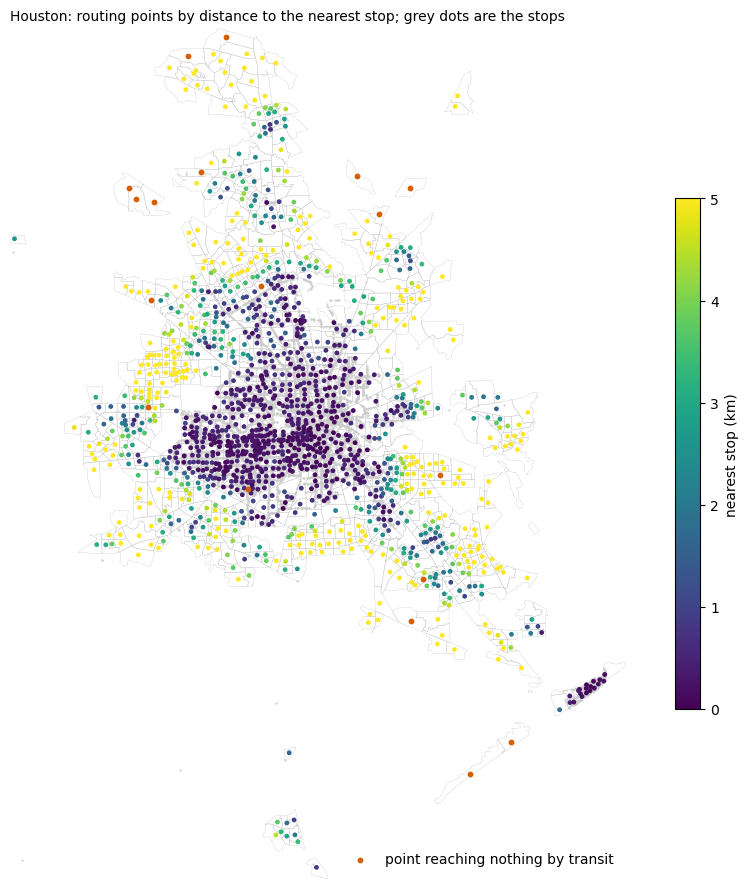

In [24]:
figure, axis = plt.subplots(figsize=(10, 9))
tracts.to_crs("EPSG:4326").plot(ax=axis, facecolor="none", edgecolor="#bbbbbb", linewidth=0.2)
stops_all.cx[west:east, south:north].plot(ax=axis, color="#cccccc", markersize=0.3)
mapped = routing_points.merge(reach[["nearest_stop_km", "isolated_home"]], left_on="id", right_index=True)
mapped.loc[~mapped["isolated_home"]].plot(column="nearest_stop_km", ax=axis, cmap="viridis", vmin=0, vmax=5, markersize=6,
                                           legend=True, legend_kwds={"shrink": 0.6, "label": "nearest stop (km)"})
if mapped["isolated_home"].any():
    mapped.loc[mapped["isolated_home"]].plot(ax=axis, color="#D55E00", markersize=10, label="point reaching nothing by transit")
axis.set_xlim(west, east)
axis.set_ylim(south, north)
axis.legend(frameon=False, loc="lower right")
axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
axis.set_title(f"{CITY}: routing points by distance to the nearest stop; grey dots are the stops", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()


Which operators serve which county: every stop of the network inside the area, assigned
to the county of the tract it falls in, by the feed it comes from. A county with stops only
from a small operator has a few park-and-ride or shuttle routes, nothing more.


In [25]:
stop_feed = {}
for index, path in enumerate(GTFS_FILES):
    with zipfile.ZipFile(path) as archive:
        ids = pd.read_csv(archive.open("stops.txt"), dtype=str, usecols=["stop_id"])["stop_id"]
    label = path.name.replace(".zip", "")
    for stop_id in ids:
        stop_feed.setdefault(stop_id, label)
        stop_feed[f"{index}:{stop_id}"] = label

in_area = gpd.sjoin(stops_all.dropna(subset=["geometry"]), tracts.to_crs("EPSG:4326")[["NAMELSADCO", "geometry"]], how="inner", predicate="within")
in_area["feed"] = in_area["id"].map(stop_feed).fillna("unknown")
stops_by_county = pd.crosstab(in_area["NAMELSADCO"], in_area["feed"])
stops_by_county["all stops"] = stops_by_county.sum(axis=1)
print(f"{len(in_area):,} stops inside the kept tracts")
stops_by_county.sort_values("all stops", ascending=False)


9,284 stops inside the kept tracts


feed,f-9-amtrak~amtrakcalifornia~amtrakcharteredvehicle,f-9-flixbus,f-9vk-metropolitantransitauthorityofharriscounty,f-9vk1-riceuniversity,f-fortbendcountytexas~tx~us,f-galveston~tx~us,f-gulfcoasttransitdistrict~tx~us,f-mdb-ntd-60103,f-thewoodlandstownship~tx~us,f-university~of~houston,f-uofhdowntownshuttle,all stops
NAMELSADCO,,,,,,,,,,,,
Harris County,1,5,8687,73,37,0,0,19,50,27,8,8907
Galveston County,0,0,0,0,0,272,11,0,0,0,0,283
Fort Bend County,0,2,56,0,3,0,0,2,0,1,0,64
Montgomery County,0,2,0,0,0,0,0,0,26,0,0,28
Brazoria County,0,0,0,0,0,0,2,0,0,0,0,2


## 11. Is it the departure time?

Most of the unreached commutes have transit at both ends but no itinerary between them
at 08:30. One suspect is the departure time itself: the Fort Bend, Woodlands and Gulf Coast
operators run express buses into central Houston only in the early morning, so a search
starting at 08:30 may find their last bus already gone. This step repeats the transit
matrix for a departure at 07:00 and compares: how many workers are reached at each time,
overall and by home county, and how many of the 08:30 unreached become reachable.


In [26]:
output_early = MATRICES / "transit-0700"
if not matrix_complete(output_early):
    started = time.time()
    TravelTimeMatrix.to_parquet(transit_network, routing_points, routing_points, output=output_early, departure=DIAGNOSTIC_DEPARTURE,
                                output_time_units="seconds", resume=output_early.exists())
    print(f"transit 07:00 {time.time() - started:6.0f} s -> {output_early}")
early = read_shards(output_early)[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "transit_0700_min"})
early["transit_0700_min"] = early["transit_0700_min"] / 60
compare = od_times[["from_id", "to_id", "workers", "transit_uncapped_min"]].merge(early, on=["from_id", "to_id"], how="left")
compare["home_county"] = compare["from_id"].map(points.set_index("tract")["NAMELSADCO"])

def reach_share(frame, column):
    return frame.loc[frame[column].notna(), "workers"].sum() / frame["workers"].sum()

rows = {"all": {"reached at 08:30": reach_share(compare, "transit_uncapped_min"), "reached at 07:00": reach_share(compare, "transit_0700_min")}}
for county, frame in compare.groupby("home_county"):
    rows[county] = {"reached at 08:30": reach_share(frame, "transit_uncapped_min"), "reached at 07:00": reach_share(frame, "transit_0700_min"), "workers": frame["workers"].sum()}
by_time = pd.DataFrame(rows).T.sort_values("workers", ascending=False, na_position="first")
unreached_0830 = compare["transit_uncapped_min"].isna()
recovered = unreached_0830 & compare["transit_0700_min"].notna()
print(f"unreached at 08:30: {compare.loc[unreached_0830, 'workers'].sum():,} workers; of these, reachable at 07:00: {compare.loc[recovered, 'workers'].sum():,} "
      f"({compare.loc[recovered, 'workers'].sum() / compare.loc[unreached_0830, 'workers'].sum():.1%}); unreached at both times: {compare.loc[unreached_0830 & ~recovered, 'workers'].sum():,}")
print("worker-weighted median minutes at 07:00:", round(weighted_median(compare.loc[compare['transit_0700_min'].notna(), 'transit_0700_min'].to_numpy(), compare.loc[compare['transit_0700_min'].notna(), 'workers'].to_numpy()), 1))
by_time.round(3)


unreached at 08:30: 637,767 workers; of these, reachable at 07:00: 1,070 (0.2%); unreached at both times: 636,697
worker-weighted median minutes at 07:00: 117.7


,reached at 08:30,reached at 07:00,workers
all,0.698,0.699,NaN
Harris County,0.783,0.783,1506625.0
Fort Bend County,0.666,0.666,263199.0
Montgomery County,0.396,0.402,152526.0
Galveston County,0.312,0.312,106140.0
Brazoria County,0.333,0.333,84049.0
Liberty County,0.213,0.213,1873.0
Waller County,0.085,0.085,258.0


## 12. Islands

If two routing points are joined whenever transit reaches one from the other, the points
fall into groups: inside a group every point can reach every other, directly or through
others, and between groups nothing connects. This step finds those groups from the 08:30
matrix and asks, for the unreached commutes, whether home and work lie in different
groups. It also measures, for each unreached commute, the straight-line distance from the
home point and from the work point to their nearest stop, against the roughly 7 km that
two hours of walking cover.


In [27]:
ids = pd.Index(routing_points["id"])
links = transit_matrix.loc[transit_matrix["travel_time"].notna()]
graph = coo_matrix((np.ones(len(links)), (ids.get_indexer(links["from_id"]), ids.get_indexer(links["to_id"]))), shape=(len(ids), len(ids)))
n_groups, labels = connected_components(graph, directed=True, connection="weak")
group = pd.Series(labels, index=ids, name="group")
group_size = group.value_counts()
print(f"{n_groups} groups of points; the largest holds {group_size.iloc[0]} points, the next ones {group_size.iloc[1:6].tolist()}")

unreached = od_times.loc[od_times["transit_uncapped_min"].isna(), ["from_id", "to_id", "workers"]].copy()
unreached["same group"] = unreached["from_id"].map(group).to_numpy() == unreached["to_id"].map(group).to_numpy()
unreached["home to nearest stop km"] = unreached["from_id"].map(reach["nearest_stop_km"])
unreached["work to nearest stop km"] = unreached["to_id"].map(reach["nearest_stop_km"])
unreached["far end"] = (unreached[["home to nearest stop km", "work to nearest stop km"]].max(axis=1) > 7)
split = unreached.groupby(["same group", "far end"])["workers"].sum().to_frame("workers")
split["share of unreached"] = split["workers"] / unreached["workers"].sum()
print("unreached workers: are home and work in the same group, and is either end more than 7 km from any stop?")
display(split.round(3))

print("distance to the nearest stop for the unreached commutes, worker-weighted percentiles (km):")
rows = {}
for column in ["home to nearest stop km", "work to nearest stop km"]:
    rows[column] = dict(zip(["p10", "p50", "p90"], weighted_percentiles(unreached[column].to_numpy(), unreached["workers"].to_numpy(), [10, 50, 90])))
display(pd.DataFrame(rows).T.round(1))

reached = od_times.loc[od_times["transit_uncapped_min"].notna(), ["from_id", "to_id", "workers"]].copy()
reached["home to nearest stop km"] = reached["from_id"].map(reach["nearest_stop_km"])
reached["work to nearest stop km"] = reached["to_id"].map(reach["nearest_stop_km"])
print("the same for the reached commutes:")
rows = {}
for column in ["home to nearest stop km", "work to nearest stop km"]:
    rows[column] = dict(zip(["p10", "p50", "p90"], weighted_percentiles(reached[column].to_numpy(), reached["workers"].to_numpy(), [10, 50, 90])))
pd.DataFrame(rows).T.round(1)


26 groups of points; the largest holds 1399 points, the next ones [10, 4, 4, 3, 3]
unreached workers: are home and work in the same group, and is either end more than 7 km from any stop?


workers  share of unreached
same group far end                             
False      False      22795               0.036
           True       54496               0.085
True       False     292134               0.458
           True      268342               0.421

distance to the nearest stop for the unreached commutes, worker-weighted percentiles (km):


,p10,p50,p90
home to nearest stop km,1.1,6.2,10.9
work to nearest stop km,0.1,2.0,8.4


the same for the reached commutes:


,p10,p50,p90
home to nearest stop km,0.2,0.9,4.6
work to nearest stop km,0.1,0.4,3.8


## 13. Which rule blocks them

cafein refuses a transit itinerary for one of four reasons, and this step counts the
unreached workers under each, measured directly rather than by straight line:

1. **No stop within a 120-minute walk of the home.** The walking time from every routing
   point to every stop is computed on the street network with cafein's walk router, which
   stops at 120 minutes like the transit search does. A home point with no stop in that
   table fails here.
2. **No stop within a 120-minute walk of the work.** The same table read from the work end.
3. **A transfer longer than 20 minutes on foot.** The transit network is rebuilt with
   transfers of up to 60 minutes and the matrix recomputed; a commute that becomes
   reachable was blocked by the transfer cap.
4. **No connecting service**, when stops exist at both ends, transfers of an hour are
   allowed, and still no sequence of rides joins them that day.


In [28]:
stops_in_area = in_area[["id", "geometry"]].drop_duplicates("id").reset_index(drop=True)
started = time.time()
walk = TravelTimeMatrix(streets, routing_points, stops_in_area, transport_mode="walk", output_time_units="minutes")
print(f"walking times from {len(routing_points):,} points to {len(stops_in_area):,} stops in {time.time() - started:.0f} s; {walk['travel_time'].notna().sum():,} pairs within 120 minutes")
walk = walk.loc[walk["travel_time"].notna()]
nearest_walk = walk.groupby("from_id")["travel_time"].min().rename("walk_to_nearest_stop_min")
stops_within = walk.groupby("from_id").size().rename("stops_within_120_min")
access = pd.DataFrame({"walk_to_nearest_stop_min": nearest_walk, "stops_within_120_min": stops_within}).reindex(routing_points["id"])
access["stops_within_120_min"] = access["stops_within_120_min"].fillna(0).astype(int)
access["stops_within_30_min"] = walk.loc[walk["travel_time"] <= 30].groupby("from_id").size().reindex(access.index, fill_value=0)
print(f"{(access['stops_within_120_min'] == 0).sum()} points have no stop within a 120-minute walk; {(access['stops_within_30_min'] == 0).sum()} have none within 30 minutes")
print("walking minutes from a point to its nearest stop:")
access["walk_to_nearest_stop_min"].describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_frame().T


walking times from 1,445 points to 9,284 stops in 1 s; 563,233 pairs within 120 minutes
270 points have no stop within a 120-minute walk; 695 have none within 30 minutes
walking minutes from a point to its nearest stop:


,count,mean,std,min,10%,50%,90%,max
walk_to_nearest_stop_min,1175.0,32.6,34.6,0.0,3.0,14.0,90.0,119.0


In [29]:
started = time.time()
if TRANSIT_ARTIFACT_TRANSFER.exists():
    transfer_network = TransportNetwork.load(TRANSIT_ARTIFACT_TRANSFER)
    print("loaded", TRANSIT_ARTIFACT_TRANSFER)
else:
    transfer_network = TransportNetwork.from_gtfs(GTFS_FILES, osm_pbf=OSM_PBF, street_modes=("walk",),
                                                  bounding_box=bounding_box, max_walking_time=TRANSFER_TEST_MINUTES)
    transfer_network.save(TRANSIT_ARTIFACT_TRANSFER)
    print("built and saved", TRANSIT_ARTIFACT_TRANSFER)
print(f"{time.time() - started:.0f} s; {transfer_network.transfer_count:,} transfers in this network, {transit_network.transfer_count:,} in the 20-minute one")

output_transfer = MATRICES / f"transit-transfer{TRANSFER_TEST_MINUTES}"
if not matrix_complete(output_transfer):
    started = time.time()
    TravelTimeMatrix.to_parquet(transfer_network, routing_points, routing_points, output=output_transfer, departure=DEPARTURE,
                                output_time_units="seconds", resume=output_transfer.exists())
    print(f"transit with {TRANSFER_TEST_MINUTES}-minute transfers {time.time() - started:6.0f} s -> {output_transfer}")
long_transfers = read_shards(output_transfer)[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "transit_transfer_min"})
long_transfers["transit_transfer_min"] = long_transfers["transit_transfer_min"] / 60


loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

loaded /scratch/project_2010423/carbon-advantage/commuting/houston/houston-transit-transfer60.cafein
4 s; 2,399,850 transfers in this network, 331,912 in the 20-minute one


In [30]:
unreached = od_times.loc[od_times["transit_uncapped_min"].isna(), ["from_id", "to_id", "workers"]].merge(long_transfers, on=["from_id", "to_id"], how="left")
unreached["home has a stop within 120 min"] = unreached["from_id"].map(access["stops_within_120_min"] > 0)
unreached["work has a stop within 120 min"] = unreached["to_id"].map(access["stops_within_120_min"] > 0)
unreached["reachable with 60-minute transfers"] = unreached["transit_transfer_min"].notna()
rule = np.select(
    [~unreached["home has a stop within 120 min"] & ~unreached["work has a stop within 120 min"],
     ~unreached["home has a stop within 120 min"],
     ~unreached["work has a stop within 120 min"],
     unreached["reachable with 60-minute transfers"]],
    ["1+2. no stop within a 120-minute walk of the home nor of the work",
     "1. no stop within a 120-minute walk of the home",
     "2. no stop within a 120-minute walk of the work",
     "3. stops at both ends, blocked only by the 20-minute transfer cap"],
    "4. stops at both ends, no connecting service even with 60-minute transfers")
by_rule = unreached.groupby(rule)["workers"].sum().to_frame("workers")
by_rule["share of unreached workers"] = by_rule["workers"] / unreached["workers"].sum()
by_rule["share of all workers"] = by_rule["workers"] / od_times["workers"].sum()
# Consistency check: a point with no stop within a 120-minute walk should reach nothing in the transit matrix.
no_stop = access.index[access["stops_within_120_min"] == 0]
reached_anyway = transit_matrix.loc[transit_matrix["from_id"].isin(no_stop) & transit_matrix["travel_time"].notna()]
print(f"{len(no_stop)} points without a stop within a 120-minute walk; the transit matrix still reaches {reached_anyway['from_id'].nunique()} of them to somewhere "
      f"({len(reached_anyway):,} pairs, median {reached_anyway['travel_time'].median() / 60 if len(reached_anyway) else float('nan'):.0f} min)")
access.to_parquet(MATRICES / f"walk-to-stops-by-point-{YEAR}.parquet")
print(f"{unreached['workers'].sum():,} unreached workers, by the rule that blocks them:")
display(by_rule.round(3))

print("for rule 4, walking minutes to the nearest stop at each end, worker-weighted percentiles:")
four = unreached.loc[pd.Series(rule, index=unreached.index).str.startswith("4")].copy()
four["home walk"] = four["from_id"].map(access["walk_to_nearest_stop_min"])
four["work walk"] = four["to_id"].map(access["walk_to_nearest_stop_min"])
rows = {column: dict(zip(["p10", "p50", "p90"], weighted_percentiles(four[column].to_numpy(), four["workers"].to_numpy(), [10, 50, 90]))) for column in ["home walk", "work walk"]}
pd.DataFrame(rows).T.round(0)


270 points without a stop within a 120-minute walk; the transit matrix still reaches 252 of them to somewhere (19,587 pairs, median 221 min)
637,767 unreached workers, by the rule that blocks them:


,workers,share of unreached workers,share of all workers
1+2. no stop within a 120-minute walk of the home nor of the work,61343,0.096,0.029
1. no stop within a 120-minute walk of the home,386347,0.606,0.183
2. no stop within a 120-minute walk of the work,126447,0.198,0.060
"3. stops at both ends, blocked only by the 20-minute transfer cap",2244,0.004,0.001
"4. stops at both ends, no connecting service even with 60-minute transfers",61386,0.096,0.029


for rule 4, walking minutes to the nearest stop at each end, worker-weighted percentiles:


,p10,p50,p90
home walk,8.0,59.0,115.0
work walk,2.0,29.0,94.0


### The walking rule cafein actually applied

The check above shows the transit matrix reaching somewhere from 252 of the 270 points
that have no stop within a 120-minute walk, so the documented 120-minute access limit was
not what bounded the search: when no walking limit is passed, cafein's matrix leaves it
unset. This cell measures the true walking time from every point to its nearest stop with
a ten-hour cap, and tabulates, by walking-time band, how many points reach anything by
transit. The band where the reach drops to zero is the limit that was really in force.


In [31]:
started = time.time()
walk_long = TravelTimeMatrix(streets, routing_points, stops_in_area, transport_mode="walk", max_street_time=600, output_time_units="minutes")
walk_long = walk_long.loc[walk_long["travel_time"].notna()]
nearest_long = walk_long.groupby("from_id")["travel_time"].min().rename("walk_to_nearest_stop_min").reindex(routing_points["id"])
print(f"walking times with a 600-minute cap in {time.time() - started:.0f} s; {nearest_long.isna().sum()} points have no stop within ten hours of walking")

reaches = transit_matrix.loc[transit_matrix["travel_time"].notna()].groupby("from_id", observed=True).size().reindex(routing_points["id"], fill_value=0)
bands = pd.cut(nearest_long, [0, 30, 60, 90, 120, 150, 180, 240, 300, 600], include_lowest=True)
by_band = pd.DataFrame({"points": bands.value_counts(sort=False),
                        "points reaching something by transit": reaches.groupby(bands, observed=False).apply(lambda s: (s > 0).sum()),
                        "mean destinations reached": reaches.groupby(bands, observed=False).mean().round(0)})
by_band.index.name = "walking minutes to the nearest stop"
display(by_band)

unreached = od_times.loc[od_times["transit_uncapped_min"].isna(), ["from_id", "to_id", "workers"]].copy()
unreached["home walk"] = unreached["from_id"].map(nearest_long)
unreached["work walk"] = unreached["to_id"].map(nearest_long)
print("unreached commutes: true walking minutes to the nearest stop at each end, worker-weighted percentiles:")
rows = {column: dict(zip(["p10", "p50", "p90"], weighted_percentiles(unreached[column].fillna(600).to_numpy(), unreached["workers"].to_numpy(), [10, 50, 90]))) for column in ["home walk", "work walk"]}
display(pd.DataFrame(rows).T.round(0))
print("share of unreached workers by the longer of the two walks:")
longest = unreached[["home walk", "work walk"]].fillna(600).max(axis=1)
shares = unreached.groupby(pd.cut(longest, [0, 60, 120, 180, 240, 600], include_lowest=True), observed=False)["workers"].sum()
(shares / shares.sum()).round(3).to_frame("share of unreached workers")


street matrix:  10%|#         | 146/1445 [00:02<00:17, 72.89it/s]

walking times with a 600-minute cap in 18 s; 20 points have no stop within ten hours of walking


,points,points reaching something by transit,mean destinations reached
walking minutes to the nearest stop,,,
"(-0.001, 30.0]",750,750,1096.0
"(30.0, 60.0]",151,151,989.0
"(60.0, 90.0]",158,158,1017.0
"(90.0, 120.0]",119,119,983.0
"(120.0, 150.0]",91,91,59.0
"(150.0, 180.0]",63,63,16.0
"(180.0, 240.0]",48,47,35.0
"(240.0, 300.0]",24,21,98.0
"(300.0, 600.0]",21,13,59.0


unreached commutes: true walking minutes to the nearest stop at each end, worker-weighted percentiles:


,p10,p50,p90
home walk,27.0,143.0,250.0
work walk,2.0,46.0,189.0


share of unreached workers by the longer of the two walks:


,share of unreached workers
"(-0.001, 60.0]",0.035
"(60.0, 120.0]",0.076
"(120.0, 180.0]",0.532
"(180.0, 240.0]",0.191
"(240.0, 600.0]",0.166


## 14. Summary: why 30 % of Houston's commutes have no transit itinerary

**The finding.** Of the 2.11 million commutes between the kept tracts, 637,767 (30.2 %)
get no public transport travel time for a departure at 08:30 on Tuesday 2026-11-10. The
routing allows a walk of up to 120 minutes to the first stop and from the last one, so
this is not a matter of a short walk being refused.

**The causes, each commute counted once** (step 13):

| rule that blocks the commute | workers | share of the unreached |
|---|---|---|
| no stop within a 120-minute walk of the home | 386,347 | 60.6 % |
| no stop within a 120-minute walk of the work | 126,447 | 19.8 % |
| no stop within 120 minutes of either end | 61,343 | 9.6 % |
| stops at both ends, no connecting service that day (even with 60-minute transfers) | 61,386 | 9.6 % |
| stops at both ends, blocked only by the 20-minute transfer cap | 2,244 | 0.4 % |

So 90 % of the unreached commutes fail because one end of the trip is more than two
hours on foot from any stop with service. The home end dominates: the median unreached
commute starts 143 minutes' walk from the nearest stop, against 14 minutes for the median
tract point overall, and 270 of the 1,445 tract points have no stop within two hours at
all. The transfer rule plays no role, and neither does the departure time: starting at
07:00 instead of 08:30 recovers 0.2 % of the unreached (step 11). The network is not
fragmented either: 97 % of the points belong to one connected transit system (step 12).
It is simply absent from the suburbs. Outside Harris County the service consists of
park-and-ride express buses into central Houston (Fort Bend Transit, The Woodlands
Township) and a few local shuttles (Connect Transit in Brazoria and Galveston counties),
and METRO's grid ends at the Harris County line, so Pearland, with the largest suburban
workforce, has no stop.

**One sentence for the paper.** For 30 % of Houston commutes no public transport
itinerary exists for a weekday departure at 08:30, even allowing two hours of walking at
each end; in 90 % of these the home or the workplace lies more than two hours on foot
from any stop with service, and only 10 % fail for lack of a connecting service between
stops that exist at both ends.

**Assumptions and limits of the routing.** The table below lists every rule in force,
whether it is cafein's default or our choice, and what it does to the result. The main
thing to keep in mind when reading the transit times is that the 120-minute walking
allowance is far beyond what anyone does: the 70 % of commutes counted as reached include
walks of an hour or more at each end, and a realistic limit of 20 to 30 minutes would
lower both the reach and the median time of the remaining commutes.


In [32]:
assumptions = pd.DataFrame([
    ("departure", "one moment, 08:30 on Tuesday 2026-11-10", "our choice, as in Helsinki and London", "no averaging over the peak; frequencies matter less than the schedule at that minute"),
    ("total travel time", "no cap", "cafein default", "very long itineraries count as reached; the p90 is 368 minutes"),
    ("walk to the first stop and from the last", "up to 120 minutes at 3.6 km/h, about 7 km, on the street network", "cafein default", "generous; sets what 'unreached' means here"),
    ("transfers between stops on foot", "up to 20 minutes", "cafein default", "no effect: lifting it to 60 minutes recovers 0.4 % of the unreached"),
    ("rides per itinerary", "up to 8", "cafein default", "not binding"),
    ("attaching points and stops to streets", "within 1,600 m straight line", "cafein default", "all Houston points and stops pass; 103 intercity stops outside the area do not"),
    ("feeds", "11 GTFS files fetched by transitio for the area; Amtrak and Flixbus included", "transitio's index for the kept-tract polygon", "METRO is the only dense network; suburban operators run peak-only express buses"),
    ("data quality", "2,878 trip instances quarantined by cafein, all file trips kept except one shuttle trip; 205 METRO validator errors are shape distances", "cafein and transitio defaults, repair off", "no effect on travel times"),
    ("tracts", "those with at most 20 km2 of land, 1,447 of 1,612, holding 79 % of the workers", "05.2.1, threshold set by the user", "the dropped fringe tracts are the least served; their commuters are not in these figures"),
    ("routing point of a tract", "resident-worker-weighted mean of its block points, snapped to a street inside the tract within 1 km", "our rule, as in London and New York", "two shore tracts without a street point left out"),
    ("car times", "free-flow, and with intersection delays at the rush profile; no parking search", "cafein defaults; profile our choice", "rush median 38 minutes, close to the Census figure"),
    ("bicycle", "street routing capped at 120 minutes", "cafein default", "35 % of commutes exceed the cap and count as unreached"),
    ("e-bike", "the bicycle's streets at 17.4 km/h on the flat against the bicycle's 15.3, no slope model, the same 120-minute cap", "cafein defaults, as in Helsinki",
     f"{100 * od_times.loc[od_times['e_bike_min'].isna(), 'workers'].sum() / od_times['workers'].sum():.0f} % of commutes exceed the cap and count as unreached"),
], columns=["rule", "value", "set by", "effect"]).set_index("rule")
pd.set_option("display.max_colwidth", 120)
assumptions


,value,set by,effect
rule,,,
departure,"one moment, 08:30 on Tuesday 2026-11-10","our choice, as in Helsinki and London",no averaging over the peak; frequencies matter less than the schedule at that minute
total travel time,no cap,cafein default,very long itineraries count as reached; the p90 is 368 minutes
walk to the first stop and from the last,"up to 120 minutes at 3.6 km/h, about 7 km, on the street network",cafein default,generous; sets what 'unreached' means here
transfers between stops on foot,up to 20 minutes,cafein default,no effect: lifting it to 60 minutes recovers 0.4 % of the unreached
rides per itinerary,up to 8,cafein default,not binding
attaching points and stops to streets,"within 1,600 m straight line",cafein default,all Houston points and stops pass; 103 intercity stops outside the area do not
feeds,11 GTFS files fetched by transitio for the area; Amtrak and Flixbus included,transitio's index for the kept-tract polygon,METRO is the only dense network; suburban operators run peak-only express buses
data quality,"2,878 trip instances quarantined by cafein, all file trips kept except one shuttle trip; 205 METRO validator errors ...","cafein and transitio defaults, repair off",no effect on travel times
tracts,"those with at most 20 km2 of land, 1,447 of 1,612, holding 79 % of the workers","05.2.1, threshold set by the user",the dropped fringe tracts are the least served; their commuters are not in these figures


267 tracts have their point more than 120 minutes' walk from any stop: 561,756.0 resident workers (24.5%) and 290,571 jobs (12.0%)
by county, resident workers in those tracts:


,resident workers beyond a 120-minute walk
NAMELSADCO,
Harris County,283153
Fort Bend County,93090
Montgomery County,81965
Brazoria County,55568
Galveston County,45323
Liberty County,2365
Waller County,292


/tmp/marinflo/3372139/ipykernel_1795435/3106007924.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  shown["beyond 120 min"] = shown["beyond 120 min"].fillna(False).astype(bool)


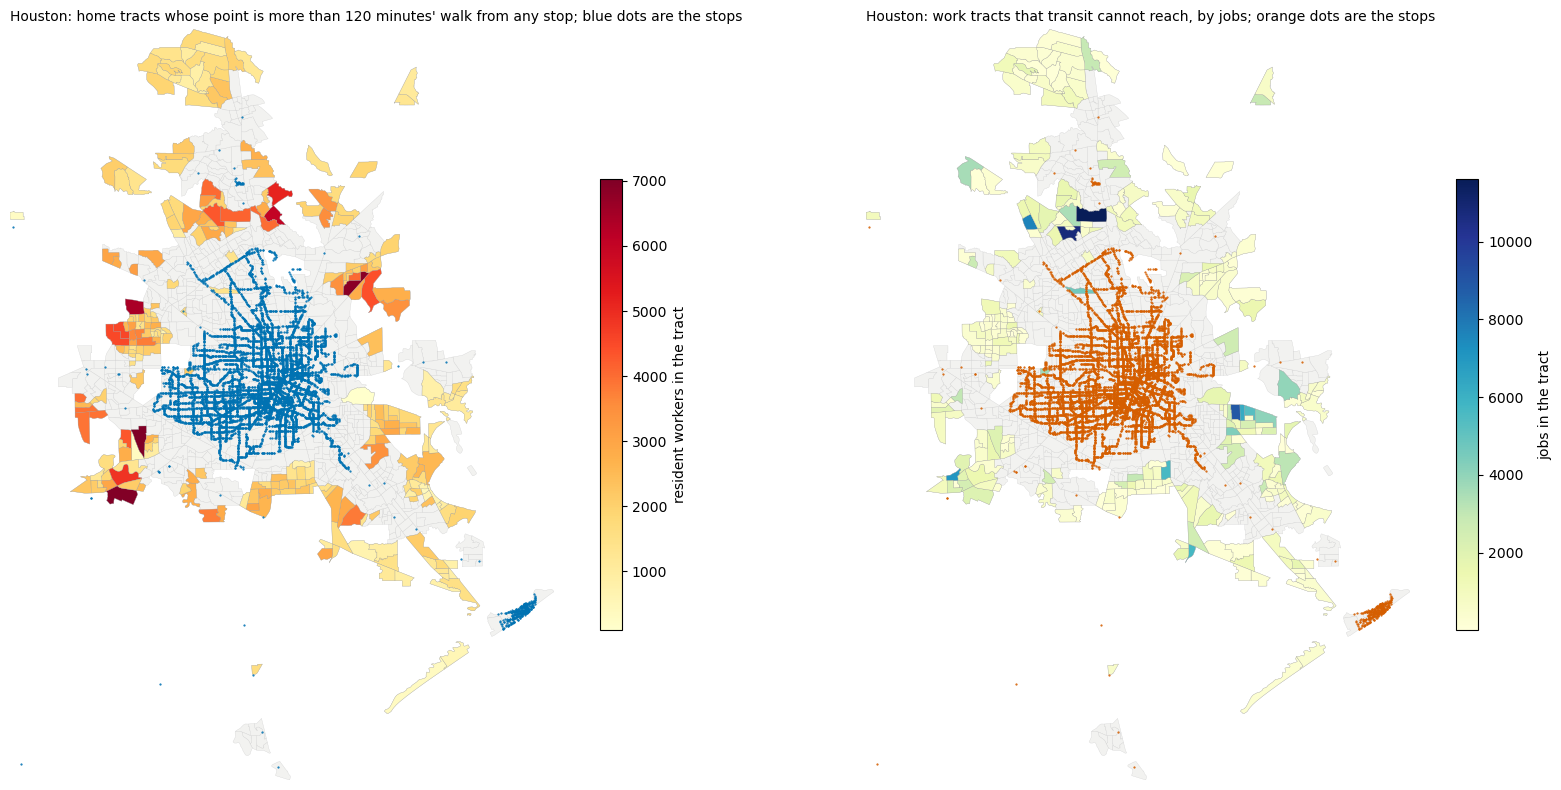

In [33]:
per_point = pd.DataFrame({"walk_to_nearest_stop_min": nearest_long}).join(points.set_index("tract")[["NAMELSADCO", "workers_home", "workers_work"]])
per_point["beyond 120 min"] = per_point["walk_to_nearest_stop_min"].isna() | (per_point["walk_to_nearest_stop_min"] > 120)
per_point.rename_axis("tract").reset_index().to_parquet(MATRICES / f"walk-to-nearest-stop-by-tract-{YEAR}.parquet", index=False)
far = per_point.loc[per_point["beyond 120 min"]]
print(f"{len(far)} tracts have their point more than 120 minutes' walk from any stop: {far['workers_home'].sum():,} resident workers ({far['workers_home'].sum() / per_point['workers_home'].sum():.1%}) "
      f"and {far['workers_work'].sum():,.0f} jobs ({far['workers_work'].sum() / per_point['workers_work'].sum():.1%})")
print("by county, resident workers in those tracts:")
display(far.groupby("NAMELSADCO")["workers_home"].sum().sort_values(ascending=False).to_frame("resident workers beyond a 120-minute walk").astype(int))

shown = tracts.to_crs("EPSG:4326").merge(per_point[["walk_to_nearest_stop_min", "beyond 120 min"]], left_on="tract", right_index=True, how="left")
# The two tracts without a routing point have no walking time; they are drawn as background only.
shown["beyond 120 min"] = shown["beyond 120 min"].fillna(False).astype(bool)
figure, axes = plt.subplots(ncols=2, figsize=(18, 8))

# Left: where the homes are, by resident workers, for the tracts beyond a two-hour walk.
shown.plot(ax=axes[0], facecolor="#f2f2f0", edgecolor="#cccccc", linewidth=0.2)
shown.loc[shown["beyond 120 min"]].plot(column="workers_home", ax=axes[0], cmap="YlOrRd", edgecolor="#999999", linewidth=0.2,
                                        legend=True, legend_kwds={"shrink": 0.6, "label": "resident workers in the tract"})
stops_all.cx[west:east, south:north].plot(ax=axes[0], color="#0072B2", markersize=0.3)
axes[0].set_title(f"{CITY}: home tracts whose point is more than 120 minutes' walk from any stop; blue dots are the stops", loc="left", fontsize=10)

# Right: the workplaces that cannot be reached, by jobs.
shown.plot(ax=axes[1], facecolor="#f2f2f0", edgecolor="#cccccc", linewidth=0.2)
shown.loc[shown["beyond 120 min"]].plot(column="workers_work", ax=axes[1], cmap="YlGnBu", edgecolor="#999999", linewidth=0.2,
                                        legend=True, legend_kwds={"shrink": 0.6, "label": "jobs in the tract"})
stops_all.cx[west:east, south:north].plot(ax=axes[1], color="#D55E00", markersize=0.3)
axes[1].set_title(f"{CITY}: work tracts that transit cannot reach, by jobs; orange dots are the stops", loc="left", fontsize=10)
for axis in axes:
    axis.set_xlim(west, east)
    axis.set_ylim(south, north)
    axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
    axis.set_axis_off()
figure.tight_layout()
